# **Section 1: Business Understanding**

### **NYC Taxi Trip Duration Prediction**

## Problem Statement

Ride-hailing and taxi services depend on accurate trip duration estimates to improve customer experience and optimize fleet management.

The objective of this project is to build a machine learning model capable of predicting the duration of a taxi trip based on information available at the start of the journey.

## Business Objective

Accurate trip duration prediction can help:

- Improve taxi dispatch efficiency
- Provide reliable estimated arrival times (ETA)
- Optimize fleet utilization
- Reduce customer waiting time
- Improve ride scheduling and resource allocation

## Machine Learning Problem

This is a supervised machine learning regression problem where:

Target Variable:
- trip_duration

Evaluation Metrics:
- MAE
- RMSE
- R² Score

# **Section 2: Import Libraries**

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# **Section 3: Data Loading and Inspection**

In [1]:
df = pd.read_csv("../dataset/nyc_taxi_trip_duration.csv")

df.head()

NameError: name 'pd' is not defined

In [2]:
print(f"Original Shape: {df.shape}")

df.info()

NameError: name 'df' is not defined

### Missing Values

In [3]:
import pandas as pd

df = pd.read_csv("../dataset/nyc_taxi_trip_duration.csv")
print("Dataset loaded successfully!")
print(df.shape)

Dataset loaded successfully!
(729322, 11)


In [4]:
print(f"Dataset shape: {df.shape}")
df.info()
print("\nMissing values per column:")
print(df.isnull().sum())

Dataset shape: (729322, 11)
<class 'pandas.DataFrame'>
RangeIndex: 729322 entries, 0 to 729321
Data columns (total 11 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   id                  729322 non-null  str    
 1   vendor_id           729322 non-null  int64  
 2   pickup_datetime     729322 non-null  str    
 3   dropoff_datetime    729322 non-null  str    
 4   passenger_count     729322 non-null  int64  
 5   pickup_longitude    729322 non-null  float64
 6   pickup_latitude     729322 non-null  float64
 7   dropoff_longitude   729322 non-null  float64
 8   dropoff_latitude    729322 non-null  float64
 9   store_and_fwd_flag  729322 non-null  str    
 10  trip_duration       729322 non-null  int64  
dtypes: float64(4), int64(3), str(4)
memory usage: 61.2 MB

Missing values per column:
id                    0
vendor_id             0
pickup_datetime       0
dropoff_datetime      0
passenger_count       0
pickup_longitud

In [5]:
df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], format="%d-%m-%Y %H:%M"
)

df["dropoff_datetime"] = pd.to_datetime(
    df["dropoff_datetime"], format="%d-%m-%Y %H:%M"
)

print(df[["pickup_datetime", "dropoff_datetime"]].dtypes)
print(df[["pickup_datetime", "dropoff_datetime"]].head())

pickup_datetime     datetime64[us]
dropoff_datetime    datetime64[us]
dtype: object
      pickup_datetime    dropoff_datetime
0 2016-02-29 16:40:00 2016-02-29 16:47:00
1 2016-03-11 23:35:00 2016-03-11 23:53:00
2 2016-02-21 17:59:00 2016-02-21 18:26:00
3 2016-01-05 09:44:00 2016-01-05 10:03:00
4 2016-02-17 06:42:00 2016-02-17 06:56:00


In [6]:
print("Trip duration (seconds):")
print(df["trip_duration"].describe())

print("\nNon-positive trip durations:")
print((df["trip_duration"] <= 0).sum())

print("\nPassenger count distribution:")
print(df["passenger_count"].value_counts().sort_index())

print("\nTrips longer than 3 hours:")
print((df["trip_duration"] > 10800).sum())

Trip duration (seconds):
count    7.293220e+05
mean     9.522291e+02
std      3.864626e+03
min      1.000000e+00
25%      3.970000e+02
50%      6.630000e+02
75%      1.075000e+03
max      1.939736e+06
Name: trip_duration, dtype: float64

Non-positive trip durations:
0

Passenger count distribution:
passenger_count
0        33
1    517415
2    105097
3     29692
4     14050
5     38926
6     24107
7         1
9         1
Name: count, dtype: int64

Trips longer than 3 hours:
1031


In [7]:
print("Longest 10 trips:")
print(
    df.nlargest(10, "trip_duration")[
        ["pickup_datetime", "dropoff_datetime",
         "passenger_count", "trip_duration"]
    ]
)

Longest 10 trips:
           pickup_datetime    dropoff_datetime  passenger_count  trip_duration
21813  2016-01-05 00:19:00 2016-01-27 11:08:00                1        1939736
259437 2016-05-31 13:00:00 2016-06-01 13:00:00                1          86391
119185 2016-06-30 16:37:00 2016-07-01 16:37:00                1          86387
177225 2016-05-12 13:48:00 2016-05-13 13:47:00                1          86378
496391 2016-05-14 04:48:00 2016-05-15 04:47:00                1          86377
90557  2016-05-26 14:55:00 2016-05-27 14:54:00                6          86369
673847 2016-02-25 15:17:00 2016-02-26 15:16:00                1          86369
163178 2016-02-20 09:00:00 2016-02-21 09:00:00                5          86367
179065 2016-02-21 00:46:00 2016-02-22 00:46:00                3          86365
248675 2016-02-07 14:04:00 2016-02-08 14:04:00                1          86364


In [8]:
# Keep realistic trip durations and passenger counts
df_clean = df[
    (df["trip_duration"] >= 60) &
    (df["trip_duration"] <= 10800) &
    (df["passenger_count"].between(1, 6))
].copy()

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))
print("\nCleaned trip-duration summary:")
print(df_clean["trip_duration"].describe())

Original rows: 729322
Cleaned rows: 724008
Rows removed: 5314

Cleaned trip-duration summary:
count    724008.000000
mean        841.430523
std         655.720546
min          60.000000
25%         401.000000
50%         666.000000
75%        1076.000000
max       10451.000000
Name: trip_duration, dtype: float64


In [9]:
import numpy as np

# Time-based features
df_clean["pickup_hour"] = df_clean["pickup_datetime"].dt.hour
df_clean["pickup_dayofweek"] = df_clean["pickup_datetime"].dt.dayofweek
df_clean["pickup_month"] = df_clean["pickup_datetime"].dt.month
df_clean["is_weekend"] = (
    df_clean["pickup_dayofweek"] >= 5
).astype(int)

# Calculate straight-line distance using the Haversine formula
lat1 = np.radians(df_clean["pickup_latitude"])
lat2 = np.radians(df_clean["dropoff_latitude"])
lon1 = np.radians(df_clean["pickup_longitude"])
lon2 = np.radians(df_clean["dropoff_longitude"])

dlat = lat2 - lat1
dlon = lon2 - lon1

a = (
    np.sin(dlat / 2) ** 2
    + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
)

df_clean["distance_km"] = (
    6371 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
)

print(
    df_clean[
        ["pickup_hour", "pickup_dayofweek", "pickup_month",
         "is_weekend", "distance_km", "trip_duration"]
    ].head()
)

   pickup_hour  pickup_dayofweek  pickup_month  is_weekend  distance_km  \
0           16                 0             2           0     1.199072   
1           23                 4             3           0     4.129111   
2           17                 6             2           1     7.250752   
3            9                 1             1           0     2.361097   
4            6                 2             2           0     4.328533   

   trip_duration  
0            400  
1           1100  
2           1635  
3           1141  
4            848  


In [10]:
print("Pickup longitude range:")
print(df_clean["pickup_longitude"].min(), df_clean["pickup_longitude"].max())

print("\nPickup latitude range:")
print(df_clean["pickup_latitude"].min(), df_clean["pickup_latitude"].max())

print("\nDistance summary (km):")
print(df_clean["distance_km"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

print("\nTrips with zero distance:")
print((df_clean["distance_km"] == 0).sum())

print("\nTrips over 100 km straight-line distance:")
print((df_clean["distance_km"] > 100).sum())

Pickup longitude range:
-121.933342 -65.89738464

Pickup latitude range:
34.7122345 51.88108444

Distance summary (km):
count    724008.000000
mean          3.458975
std           4.349350
min           0.000000
50%           2.108577
90%           7.663082
95%          11.022068
99%          20.775513
max        1240.908676
Name: distance_km, dtype: float64

Trips with zero distance:
2088

Trips over 100 km straight-line distance:
10


In [11]:
# Approximate NYC-area bounding box
df_model = df_clean[
    df_clean["pickup_longitude"].between(-74.3, -73.6)
    & df_clean["dropoff_longitude"].between(-74.3, -73.6)
    & df_clean["pickup_latitude"].between(40.4, 41.0)
    & df_clean["dropoff_latitude"].between(40.4, 41.0)
    & (df_clean["distance_km"] > 0)
    & (df_clean["distance_km"] <= 100)
].copy()

print("Before geographic filtering:", len(df_clean))
print("After geographic filtering:", len(df_model))
print("Rows removed:", len(df_clean) - len(df_model))

print("\nFinal distance summary:")
print(df_model["distance_km"].describe())

Before geographic filtering: 724008
After geographic filtering: 721693
Rows removed: 2315

Final distance summary:
count    721693.000000
mean          3.454192
std           3.889543
min           0.000424
25%           1.251581
50%           2.114407
75%           3.899256
max          47.765129
Name: distance_km, dtype: float64


In [12]:
from sklearn.model_selection import train_test_split

features = [
    "vendor_id",
    "passenger_count",
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude",
    "pickup_hour",
    "pickup_dayofweek",
    "pickup_month",
    "is_weekend",
    "distance_km",
]

X = df_model[features]
y = df_model["trip_duration"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Number of features:", len(features))

Training rows: 577354
Testing rows: 144339
Number of features: 11


In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time

model_lr = LinearRegression()

start_time = time.time()
model_lr.fit(X_train, y_train)
lr_train_time = time.time() - start_time

lr_predictions = model_lr.predict(X_test)

lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))
lr_r2 = r2_score(y_test, lr_predictions)

print("Linear Regression Results")
print(f"MAE: {lr_mae:.2f} seconds")
print(f"RMSE: {lr_rmse:.2f} seconds")
print(f"R² Score: {lr_r2:.4f}")
print(f"Training time: {lr_train_time:.2f} seconds")

Linear Regression Results
MAE: 278.76 seconds
RMSE: 410.09 seconds
R² Score: 0.6063
Training time: 0.66 seconds


In [14]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time

model_dt = DecisionTreeRegressor(
    max_depth=15,
    min_samples_leaf=10,
    random_state=42
)

start_time = time.time()
model_dt.fit(X_train, y_train)
dt_train_time = time.time() - start_time

dt_predictions = model_dt.predict(X_test)

dt_mae = mean_absolute_error(y_test, dt_predictions)
dt_rmse = np.sqrt(mean_squared_error(y_test, dt_predictions))
dt_r2 = r2_score(y_test, dt_predictions)

print("Decision Tree Results")
print(f"MAE: {dt_mae:.2f} seconds")
print(f"RMSE: {dt_rmse:.2f} seconds")
print(f"R² Score: {dt_r2:.4f}")
print(f"Training time: {dt_train_time:.2f} seconds")

Decision Tree Results
MAE: 212.15 seconds
RMSE: 330.52 seconds
R² Score: 0.7443
Training time: 6.23 seconds


In [15]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time

model_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

start_time = time.time()
model_rf.fit(X_train, y_train)
rf_train_time = time.time() - start_time

rf_predictions = model_rf.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Results")
print(f"MAE: {rf_mae:.2f} seconds")
print(f"RMSE: {rf_rmse:.2f} seconds")
print(f"R² Score: {rf_r2:.4f}")
print(f"Training time: {rf_train_time:.2f} seconds")

Random Forest Results
MAE: 196.42 seconds
RMSE: 308.28 seconds
R² Score: 0.7775
Training time: 106.13 seconds


In [16]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time

model_gb = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

start_time = time.time()
model_gb.fit(X_train, y_train)
gb_train_time = time.time() - start_time

gb_predictions = model_gb.predict(X_test)

gb_mae = mean_absolute_error(y_test, gb_predictions)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_predictions))
gb_r2 = r2_score(y_test, gb_predictions)

print("Gradient Boosting Results")
print(f"MAE: {gb_mae:.2f} seconds")
print(f"RMSE: {gb_rmse:.2f} seconds")
print(f"R² Score: {gb_r2:.4f}")
print(f"Training time: {gb_train_time:.2f} seconds")

Gradient Boosting Results
MAE: 222.48 seconds
RMSE: 341.87 seconds
R² Score: 0.7264
Training time: 129.45 seconds


In [17]:
results = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "MAE (sec)": lr_mae,
        "RMSE (sec)": lr_rmse,
        "R²": lr_r2,
        "Training Time (sec)": lr_train_time
    },
    {
        "Model": "Decision Tree",
        "MAE (sec)": dt_mae,
        "RMSE (sec)": dt_rmse,
        "R²": dt_r2,
        "Training Time (sec)": dt_train_time
    },
    {
        "Model": "Random Forest",
        "MAE (sec)": rf_mae,
        "RMSE (sec)": rf_rmse,
        "R²": rf_r2,
        "Training Time (sec)": rf_train_time
    },
    {
        "Model": "Gradient Boosting",
        "MAE (sec)": gb_mae,
        "RMSE (sec)": gb_rmse,
        "R²": gb_r2,
        "Training Time (sec)": gb_train_time
    }
])

results = results.sort_values("MAE (sec)").round(3)
display(results)

,Model,MAE (sec),RMSE (sec),R²,Training Time (sec)
2,Random Forest,196.418,308.283,0.778,106.128
1,Decision Tree,212.154,330.524,0.744,6.225
3,Gradient Boosting,222.478,341.873,0.726,129.446
0,Linear Regression,278.761,410.090,0.606,0.658


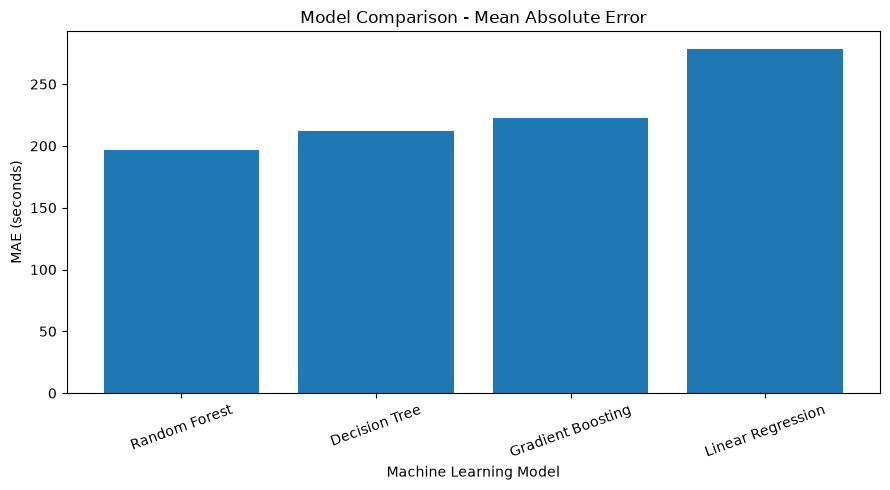

In [18]:
import matplotlib.pyplot as plt

plot_results = results.sort_values("MAE (sec)")

plt.figure(figsize=(9, 5))
plt.bar(plot_results["Model"], plot_results["MAE (sec)"])
plt.title("Model Comparison - Mean Absolute Error")
plt.xlabel("Machine Learning Model")
plt.ylabel("MAE (seconds)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

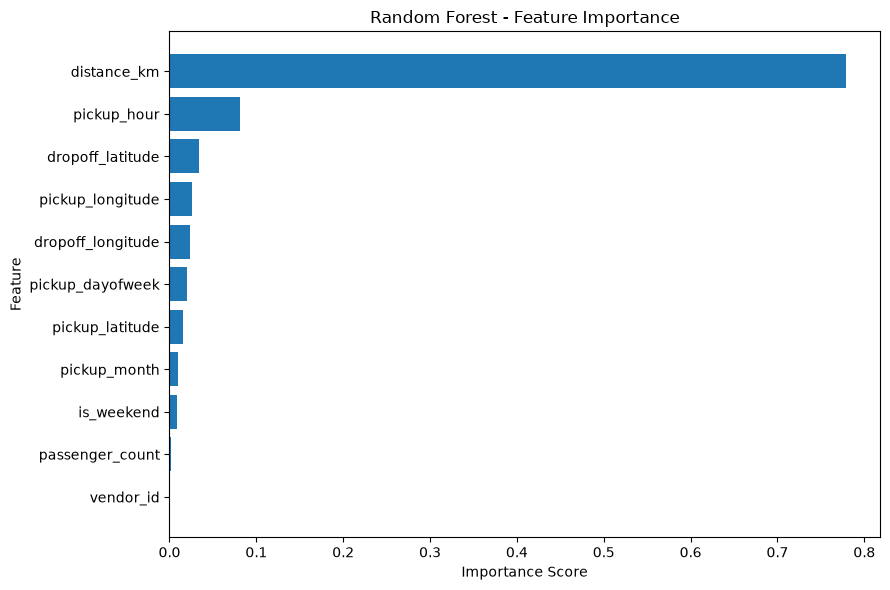

In [19]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": model_rf.feature_importances_
})

importance = importance.sort_values(
    "Importance", ascending=True
)

plt.figure(figsize=(9, 6))
plt.barh(importance["Feature"], importance["Importance"])
plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [4]:
df.isnull().sum()

,0
id,0
vendor_id,0
pickup_datetime,0
dropoff_datetime,0
passenger_count,0
pickup_longitude,0
pickup_latitude,0
dropoff_longitude,0
dropoff_latitude,0
store_and_fwd_flag,0


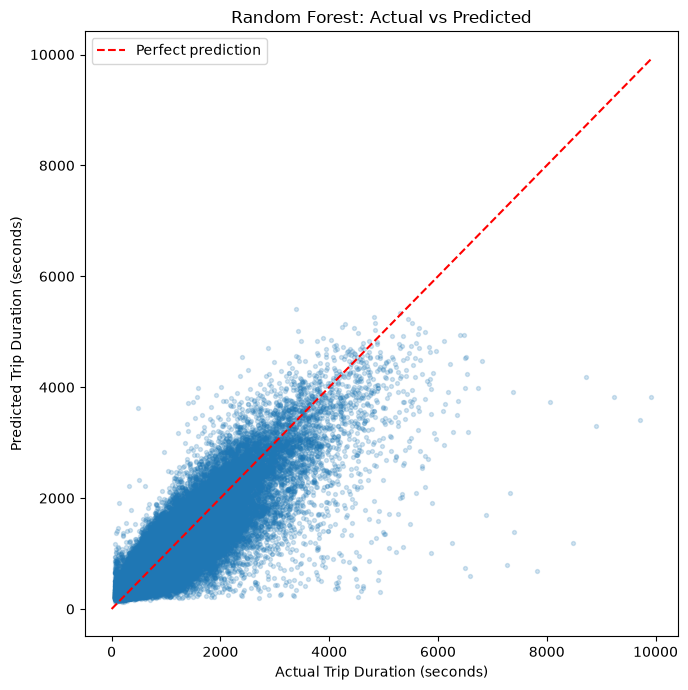

In [20]:
plt.figure(figsize=(7, 7))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.2,
    s=8
)

max_value = max(y_test.max(), rf_predictions.max())

plt.plot(
    [0, max_value],
    [0, max_value],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual Trip Duration (seconds)")
plt.ylabel("Predicted Trip Duration (seconds)")
plt.title("Random Forest: Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()

### Duplicate values inspection

In [21]:
df_model.to_csv(
    "../dataset/nyc_taxi_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")
print("Rows:", len(df_model))
print("Columns:", len(df_model.columns))

Cleaned dataset saved successfully!
Rows: 721693
Columns: 16


In [6]:
df.duplicated().sum()

np.int64(0)

### Numerical Summary

In [7]:
df.describe()

,vendor_id,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration
count,729322.000000,729322.000000,729322.000000,729322.000000,729322.000000,729322.000000,7.293220e+05
mean,1.535403,1.662055,-73.973513,40.750919,-73.973422,40.751775,9.522291e+02
std,0.498745,1.312446,0.069754,0.033594,0.069588,0.036037,3.864626e+03
min,1.000000,0.000000,-121.933342,34.712235,-121.933304,32.181141,1.000000e+00
25%,1.000000,1.000000,-73.991859,40.737335,-73.991318,40.735931,3.970000e+02
50%,2.000000,1.000000,-73.981758,40.754070,-73.979759,40.754509,6.630000e+02
75%,2.000000,2.000000,-73.967361,40.768314,-73.963036,40.769741,1.075000e+03
max,2.000000,9.000000,-65.897385,51.881084,-65.897385,43.921028,1.939736e+06


### Section Summary

The dataset contains NYC taxi trip records along with trip duration as the target variable.

Key observations from the inspection phase:

- The dataset contains 729322 rows and 11 columns.
- No missing values were detected.
- No duplicate records were found.
- Numerical features appear within expected ranges, although further validation is required for geographic coordinates and trip duration values.
- Datetime features are currently stored as object type and will require conversion before analysis.

The dataset is sufficiently clean to proceed with detailed validation and preprocessing.

# **Section 4: Data Cleaning**

### **4.1 Convert Datetime Columns**

In [8]:
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])

df['dropoff_datetime'] = pd.to_datetime(df['dropoff_datetime'])

In [9]:
df[['pickup_datetime','dropoff_datetime']].dtypes

,0
pickup_datetime,datetime64[ns]
dropoff_datetime,datetime64[ns]


###**4.2 Coordinate Validation**

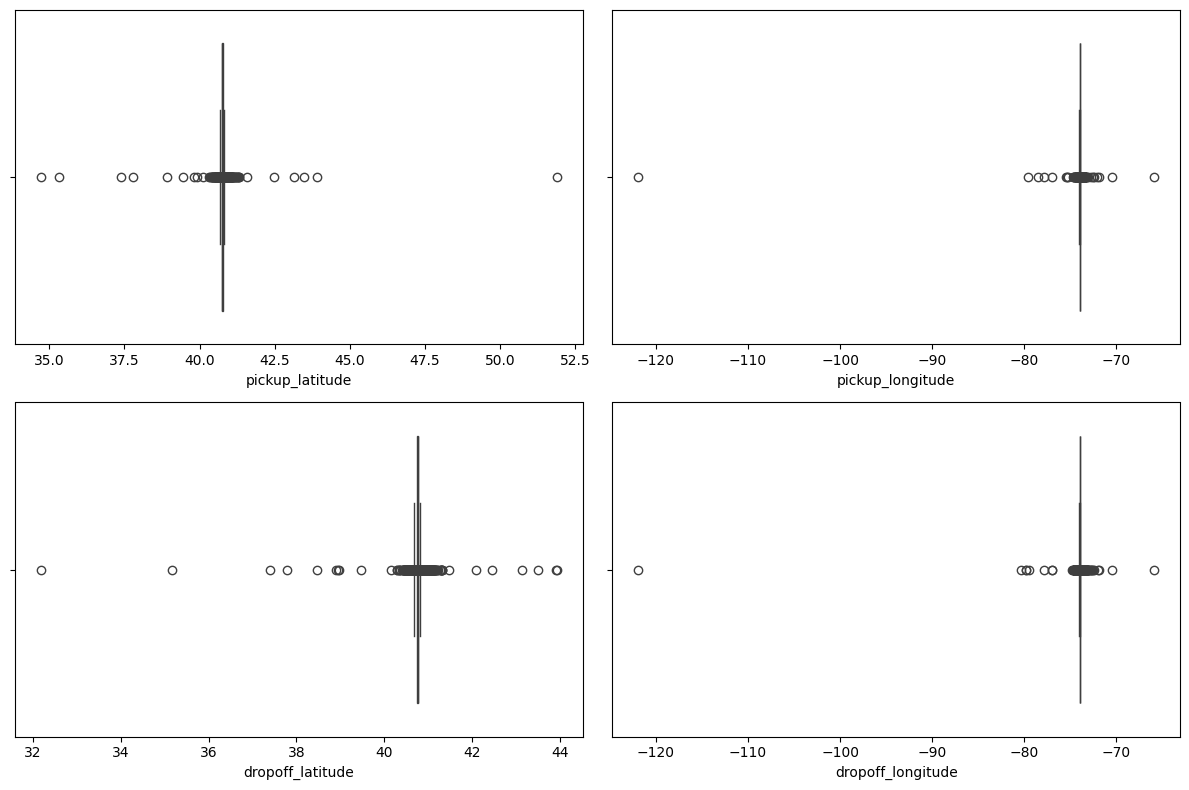

In [10]:
fig, axes = plt.subplots(2,2, figsize=(12,8))

sns.boxplot(x=df['pickup_latitude'], ax=axes[0,0])
sns.boxplot(x=df['pickup_longitude'], ax=axes[0,1])
sns.boxplot(x=df['dropoff_latitude'], ax=axes[1,0])
sns.boxplot(x=df['dropoff_longitude'], ax=axes[1,1])

plt.tight_layout()
plt.show()

###**4.3 Trip Duration Validation**

In [11]:
df['trip_duration'].describe(percentiles=[0.01,0.05,0.95,0.99])

,trip_duration
count,7.293220e+05
mean,9.522291e+02
std,3.864626e+03
min,1.000000e+00
1%,8.700000e+01
5%,1.800000e+02
50%,6.630000e+02
95%,2.102000e+03
99%,3.429000e+03
max,1.939736e+06


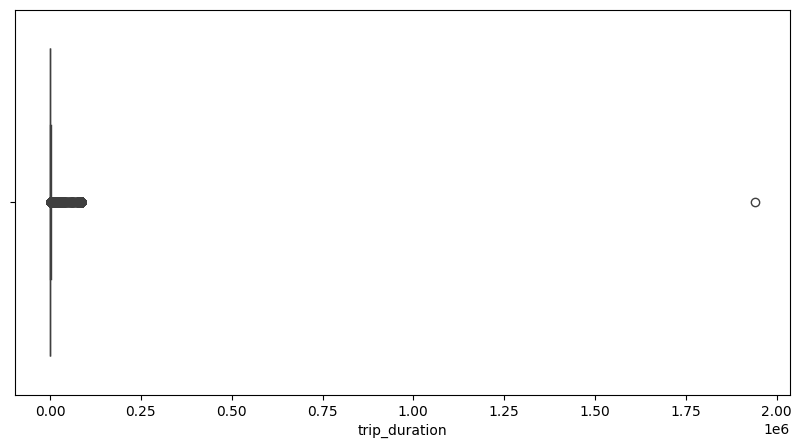

In [12]:
plt.figure(figsize=(10,5))

sns.boxplot(x=df['trip_duration'])

plt.show()

### **4.4 Outlier Treatment Strategy**

Instead of using a purely statistical method such as IQR, domain knowledge was used to identify unrealistic observations.

Geographic coordinates outside the New York City region were treated as invalid and removed.

Trip durations shorter than one minute and longer than two hours were also removed, as these values are unlikely to represent normal taxi operations and may result from recording errors.

This approach preserves genuine traffic-related variation while eliminating clearly invalid observations.

#### Remove Invalid Coordinates

In [26]:
df = df[
    (df['pickup_latitude'].between(40.5, 41.0)) &
    (df['dropoff_latitude'].between(40.5, 41.0)) &
    (df['pickup_longitude'].between(-74.3, -73.5)) &
    (df['dropoff_longitude'].between(-74.3, -73.5))
]

In [27]:
print(df.shape)

(723758, 11)


#### Remove Impossible Durations

In [28]:
df = df[
    (df['trip_duration'] >= 60) &
    (df['trip_duration'] <= 7200)
]

In [29]:
df['trip_duration'].describe(
    percentiles=[0.01,0.05,0.95,0.99]
)

,trip_duration
count,723758.000000
mean,840.327176
std,651.180490
min,60.000000
1%,110.000000
5%,189.000000
50%,665.000000
95%,2084.000000
99%,3302.000000
max,7123.000000


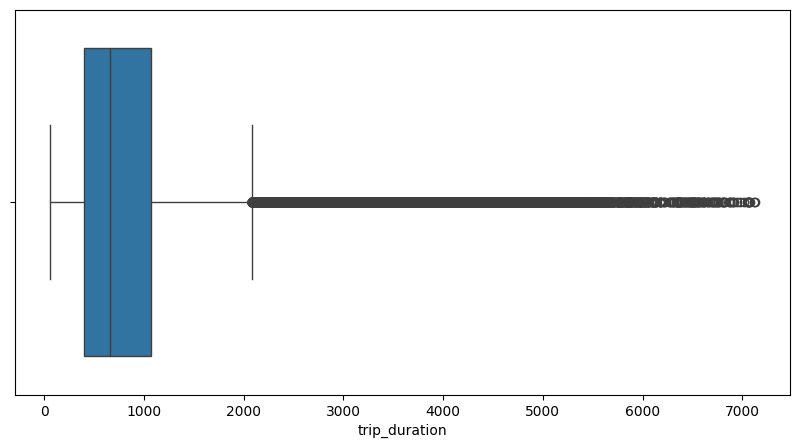

In [30]:
plt.figure(figsize=(10,5))

sns.boxplot(x=df['trip_duration'])

plt.show()

In [31]:
print(f"data set shape after cleaning: {df.shape}")

data set shape after cleaning: (723758, 11)


### Section Summary

Data cleaning focused on validating the geographic and temporal consistency of taxi trips.

Actions performed:

- Converted datetime columns into appropriate datetime format.
- Removed records containing invalid pickup or dropoff coordinates.
- Removed trips shorter than one minute.
- Removed trips longer than two hours.

Domain-based validation was preferred over purely statistical outlier removal to preserve realistic traffic behavior while eliminating clearly erroneous records.

The cleaned dataset is now suitable for exploratory data analysis and predictive modeling.

# **Section 5: Exploratory Data Analysis (EDA)**

###**5.1 Target Variable Analysis**

####Summary Statistics

In [32]:
df['trip_duration'].describe()

,trip_duration
count,723758.000000
mean,840.327176
std,651.180490
min,60.000000
25%,401.000000
50%,665.000000
75%,1076.000000
max,7123.000000


#### Distribution of Target Variable

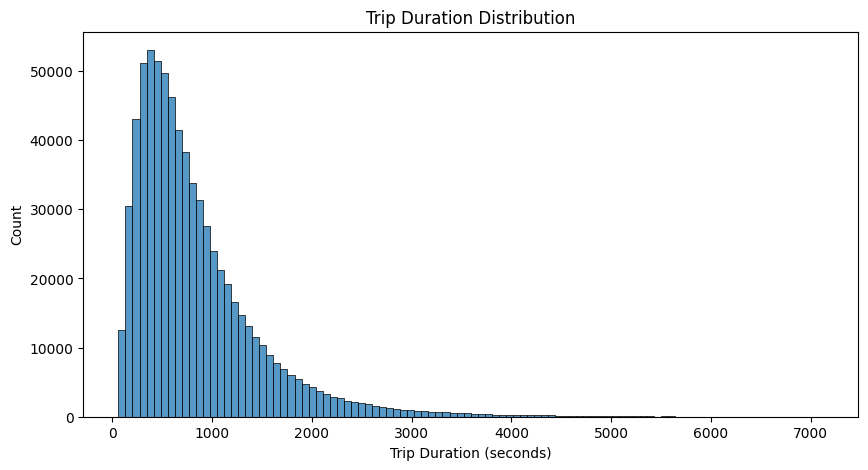

In [33]:
plt.figure(figsize=(10,5))

sns.histplot(
    df['trip_duration'],
    bins=100
)

plt.title('Trip Duration Distribution')
plt.xlabel('Trip Duration (seconds)')
plt.show()

#### Log Transformed Distribution

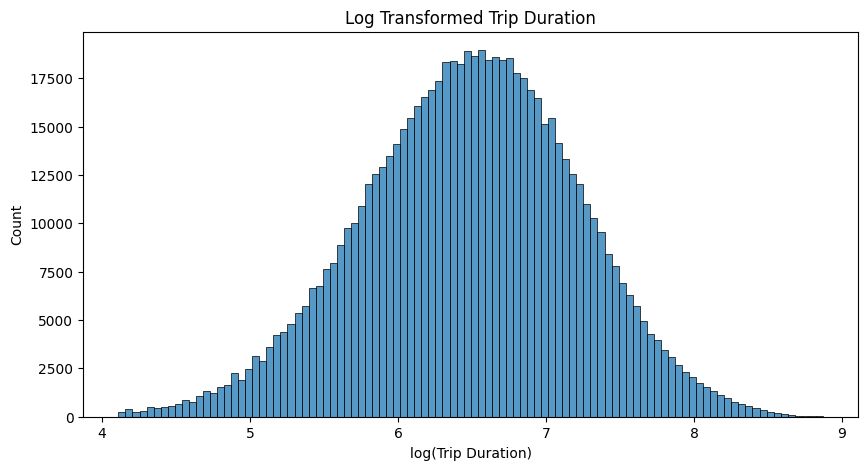

In [34]:
plt.figure(figsize=(10,5))

sns.histplot(
    np.log1p(df['trip_duration']),
    bins=100
)

plt.title('Log Transformed Trip Duration')
plt.xlabel('log(Trip Duration)')
plt.show()

#### Skewness

In [35]:
print(
    "Skewness:",
    df['trip_duration'].skew()
)

Skewness: 2.1978713559748955


#### Kurtosis

In [40]:
print("Kurtosis:", df['trip_duration'].kurtosis())

Kurtosis: 7.695521983132821


#### Boxplot

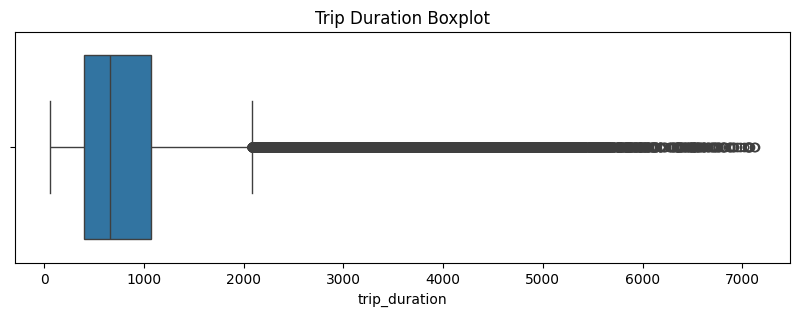

In [36]:
plt.figure(figsize=(10,3))

sns.boxplot(
    x=df['trip_duration']
)

plt.title("Trip Duration Boxplot")
plt.show()

#### Discussion

The target variable exhibits substantial positive skewness (2.20), indicating that most trips are relatively short while a smaller number of trips extend to much longer durations.

The kurtosis value (7.70) suggests heavier tails than a normal distribution, meaning extreme trip durations occur more frequently than would be expected under a Gaussian distribution.

After applying a logarithmic transformation, the distribution becomes considerably more symmetric and closer to normality. This observation suggests that modeling the log-transformed target may improve regression performance and reduce the influence of extreme observations.

### **5.2 Univariate Analysis**

#### Vendor ID

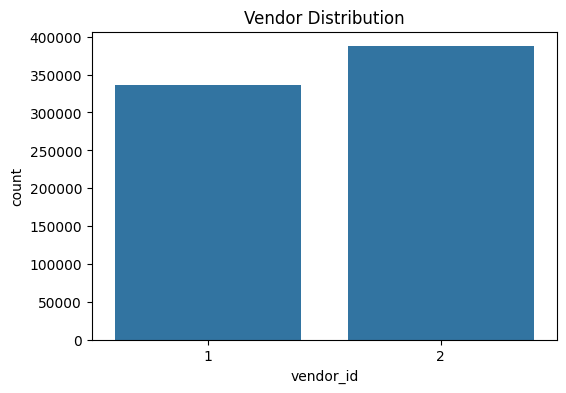

,proportion
vendor_id,
2,53.543173
1,46.456827


In [41]:
plt.figure(figsize=(6,4))

sns.countplot(
    x='vendor_id',
    data=df
)

plt.title('Vendor Distribution')
plt.show()

df['vendor_id'].value_counts(normalize=True)*100

#### Passenger Count

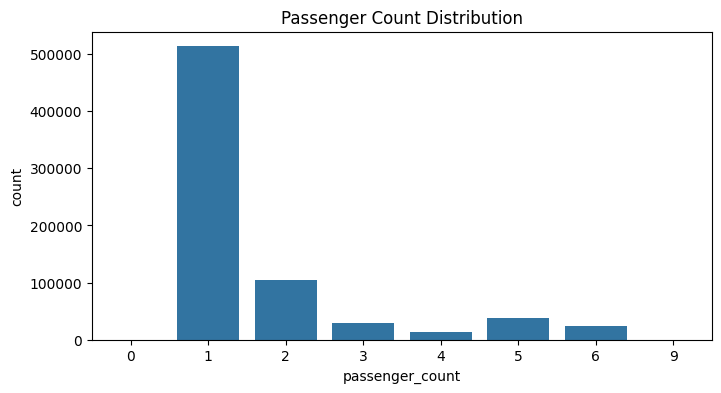

,passenger_count
count,723758.000000
mean,1.662766
std,1.312753
min,0.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,9.000000


In [43]:
plt.figure(figsize=(8,4))

sns.countplot(
    x='passenger_count',
    data=df
)

plt.title('Passenger Count Distribution')
plt.show()

df['passenger_count'].describe()

#### Store and Forward Flag

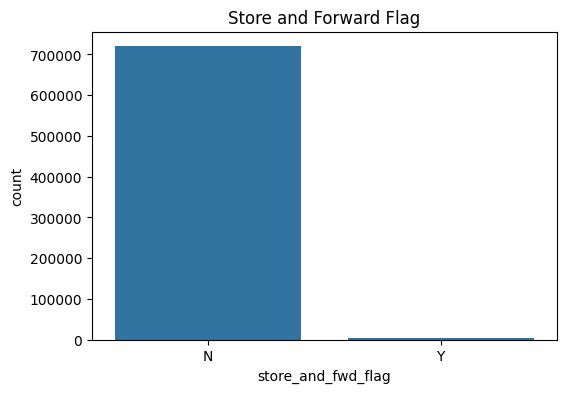

,proportion
store_and_fwd_flag,
N,99.452303
Y,0.547697


In [44]:
plt.figure(figsize=(6,4))

sns.countplot(
    x='store_and_fwd_flag',
    data=df
)

plt.title('Store and Forward Flag')
plt.show()

df['store_and_fwd_flag'].value_counts(normalize=True)*100

#### Discussion

The categorical variables show expected operational patterns within the NYC taxi system.

Vendor distribution appears relatively balanced, reducing the likelihood of vendor-specific sampling bias.

Passenger counts are concentrated around one or two passengers, indicating that most taxi trips involve individual travelers or small groups.

The store-and-forward flag is dominated by one category, suggesting that delayed transmission events are relatively uncommon and may have limited predictive value.

###**5.3 Temporal Analysis**

Objective

Understand how trip patterns vary across:

* Hour of day
* Day of week
* Month
* Weekday vs Weekend

#### Feature Extraction

In [45]:
df['pickup_hour'] = df['pickup_datetime'].dt.hour
df['pickup_day'] = df['pickup_datetime'].dt.day
df['pickup_month'] = df['pickup_datetime'].dt.month
df['pickup_weekday'] = df['pickup_datetime'].dt.day_name()

df['is_weekend'] = df['pickup_datetime'].dt.weekday >= 5

#### **5.3.1 Trip Distribution by Hour**

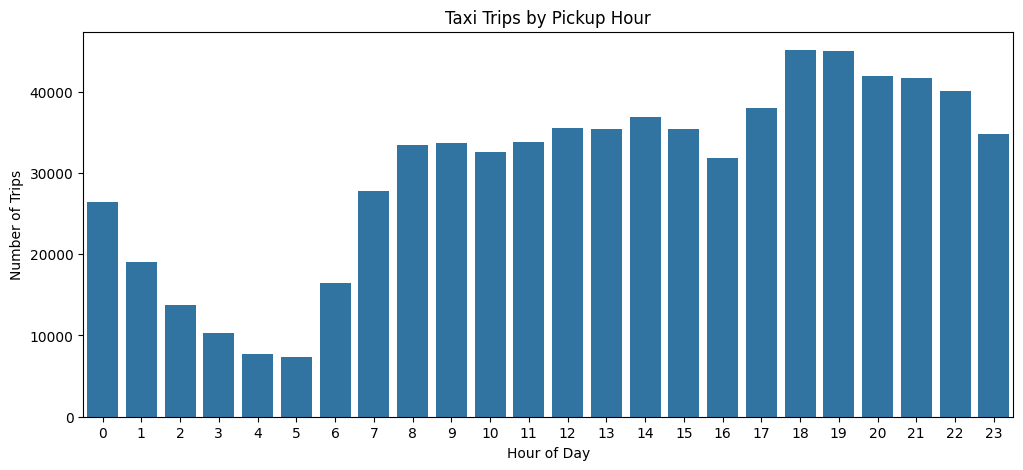

In [46]:
plt.figure(figsize=(12,5))

sns.countplot(
    x='pickup_hour',
    data=df
)

plt.title('Taxi Trips by Pickup Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Trips')

plt.show()

##### Average Trip Duration by Hour

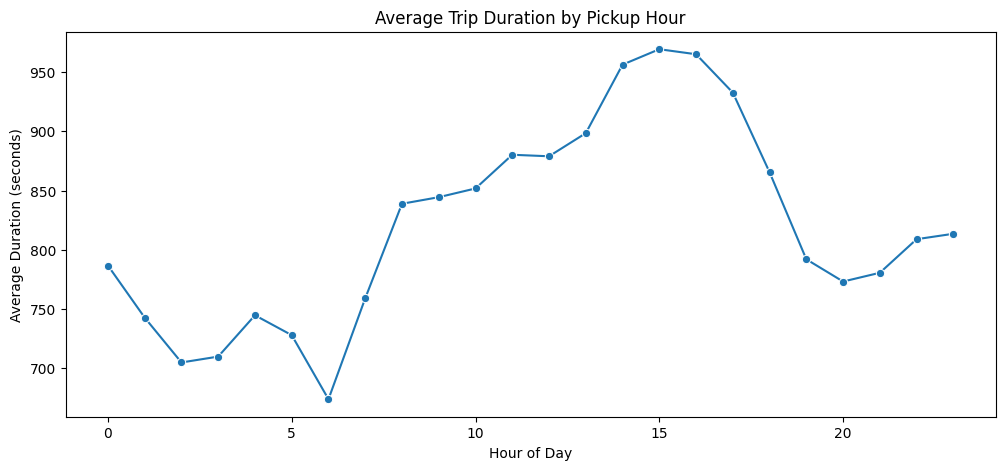

In [47]:
hourly_duration = (
    df.groupby('pickup_hour')['trip_duration']
      .mean()
      .reset_index()
)

plt.figure(figsize=(12,5))

sns.lineplot(
    data=hourly_duration,
    x='pickup_hour',
    y='trip_duration',
    marker='o'
)

plt.title('Average Trip Duration by Pickup Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Average Duration (seconds)')

plt.show()

##### Discussion

Trip activity exhibits clear diurnal patterns, with demand increasing sharply during morning and evening commuting periods.

Average trip duration is lowest during early morning hours when traffic congestion is minimal and increases noticeably during peak commuting periods.

These findings indicate that pickup_hour captures both demand fluctuations and traffic conditions, making it a potentially important predictor of trip duration.

#### **5.3.2 Day-of-Week Analysis**

##### Trip Counts by Weekday

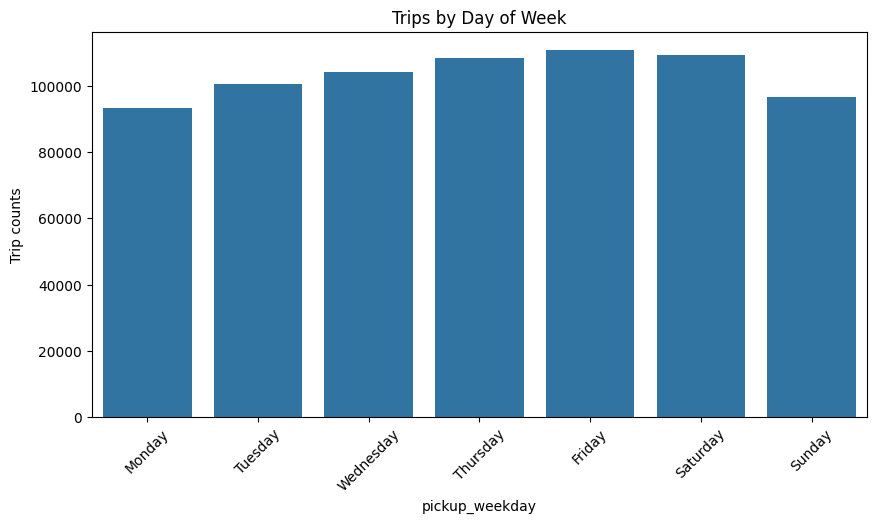

In [53]:
weekday_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]

plt.figure(figsize=(10,5))

sns.countplot(
    x='pickup_weekday',
    data=df,
    order=weekday_order
)

plt.title('Trips by Day of Week')

plt.xticks(rotation=45)
plt.ylabel('Day')
plt.ylabel('Trip counts')

plt.show()

##### Average Duration by Weekday

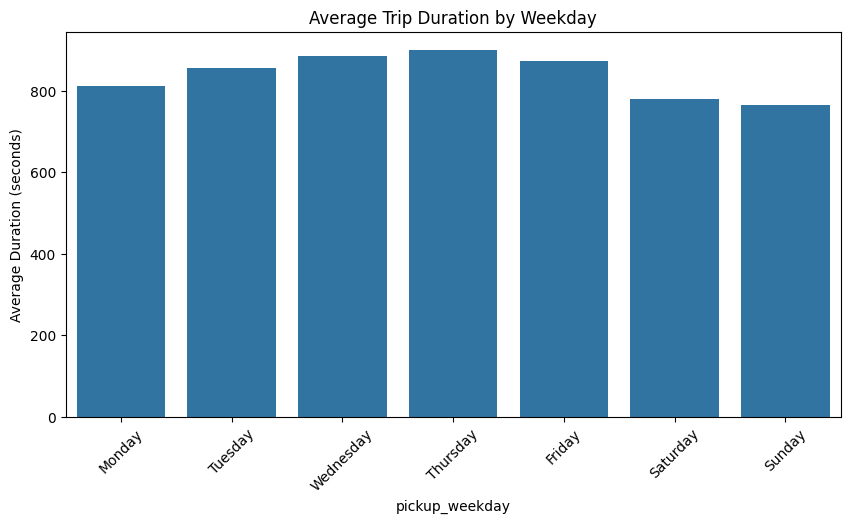

In [55]:
weekday_duration = (
    df.groupby('pickup_weekday')['trip_duration']
      .mean()
      .reindex(weekday_order)
)

plt.figure(figsize=(10,5))

sns.barplot(
    x=weekday_duration.index,
    y=weekday_duration.values
)

plt.title('Average Trip Duration by Weekday')
plt.ylabel('Day')
plt.ylabel('Average Duration (seconds)')

plt.xticks(rotation=45)

plt.show()

##### Discussion

Trip demand is higher during weekdays, particularly toward the end of the work week.

Average trip durations are generally longer on weekdays than weekends, suggesting the influence of commuter traffic and congestion.

The pickup_weekday feature appears likely to contribute predictive information regarding both travel demand and traffic patterns.

#### **5.3.3 Weekend vs Weekday**

##### Trip Counts

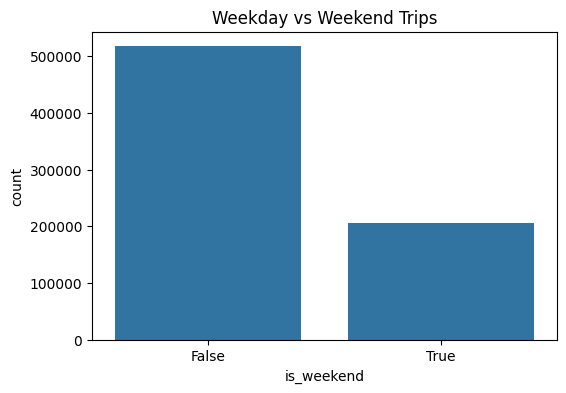

In [56]:
plt.figure(figsize=(6,4))

sns.countplot(
    x='is_weekend',
    data=df
)

plt.title('Weekday vs Weekend Trips')

plt.show()

##### Average Duration

In [59]:
weekend_duration = (
    df.groupby('is_weekend')['trip_duration']
      .mean()
)

weekend_duration

,trip_duration
is_weekend,
False,866.893266
True,773.652232


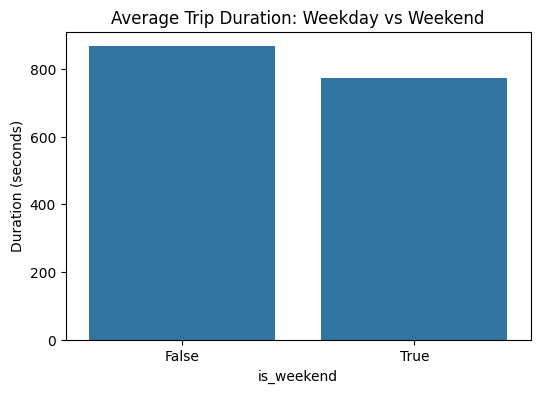

In [58]:
plt.figure(figsize=(6,4))

sns.barplot(
    x=weekend_duration.index,
    y=weekend_duration.values
)

plt.title('Average Trip Duration: Weekday vs Weekend')

plt.ylabel('Duration (seconds)')

plt.show()

##### Discussion

Weekday trips significantly outnumber weekend trips.

Average trip duration is higher on weekdays than weekends, indicating that weekday traffic conditions may contribute to longer travel times.

The is_weekend feature captures meaningful operational differences and should be retained for modeling.

#### **5.3.4 Monthly Analysis**

#####Trip Counts by Month

In [66]:
month_names = {
    1: 'January', 2: 'February', 3: 'March', 4: 'April',
    5: 'May', 6: 'June', 7: 'July', 8: 'August',
    9: 'September', 10: 'October', 11: 'November', 12: 'December'
}

df['pickup_month_name'] = df['pickup_month'].map(month_names)

# Get the order of months present in the dataframe to maintain consistency
present_months_order = [month_names[m] for m in sorted(df['pickup_month'].unique())]

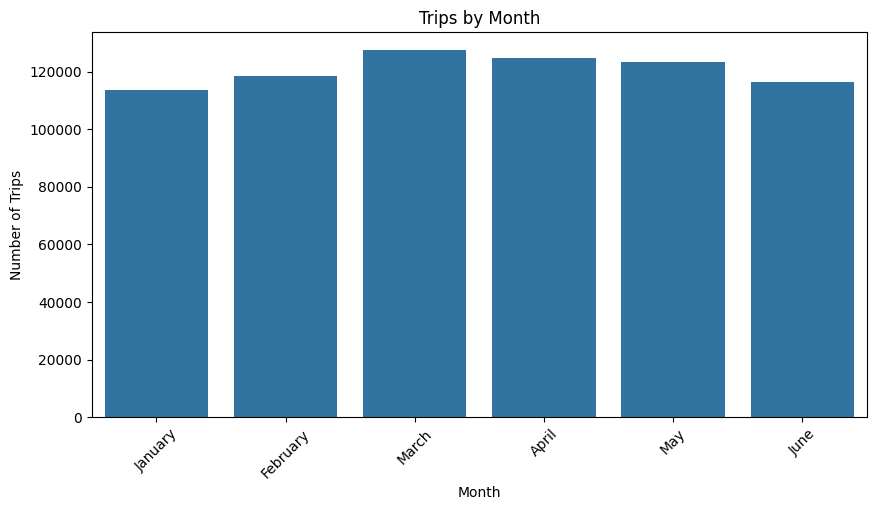

In [69]:
plt.figure(figsize=(10,5))

sns.countplot(
    x='pickup_month_name',
    data=df,
    order=present_months_order
)

plt.title('Trips by Month')
plt.xlabel('Month')
plt.ylabel('Number of Trips')
plt.xticks(rotation=45)

plt.show()

##### Average Duration by Month

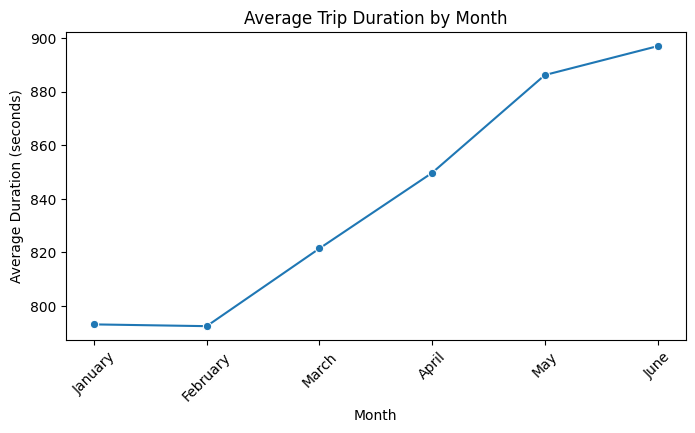

In [72]:
monthly_duration = (
    df.groupby('pickup_month')['trip_duration']
      .mean()
      .reset_index()
)

# Add month names to the monthly_duration DataFrame
monthly_duration['pickup_month_name'] = monthly_duration['pickup_month'].map(month_names)

# Sort by the month order defined earlier for consistent plotting
monthly_duration['pickup_month_order'] = monthly_duration['pickup_month'].apply(lambda x: present_months_order.index(month_names[x]))
monthly_duration = monthly_duration.sort_values('pickup_month_order')

plt.figure(figsize=(8,4))

sns.lineplot(
    data=monthly_duration,
    x='pickup_month_name',
    y='trip_duration',
    marker='o'
)

plt.title('Average Trip Duration by Month')
plt.xlabel('Month')
plt.ylabel('Average Duration (seconds)')
plt.xticks(rotation=45)

plt.show()

##### Discussion

Average trip duration shows a gradual increase from January through June.

This pattern may reflect seasonal variations in travel demand, traffic conditions, weather, or tourism activity.

The pickup_month feature may therefore provide useful contextual information for duration prediction.

#### Temporal Analysis Summary

Temporal features provide significant insights into taxi trip patterns and duration.

- **Hourly Patterns**: Both trip frequency and average duration exhibit strong hourly variations, with peaks during morning and evening rush hours and shorter durations in the early morning, indicating the direct influence of congestion.
- **Day-of-Week Patterns**: Weekdays consistently show higher trip counts and longer average durations compared to weekends, reflecting distinct commuting behaviors and traffic conditions.
- **Monthly Trends**: A clear increasing trend in average trip duration from January to June suggests seasonal influences, likely due to improving weather and increased activity or tourism.

These distinct temporal variations highlight that `pickup_hour`, `pickup_weekday`, and `pickup_month` are crucial features for accurately predicting trip duration, as they capture significant demand and congestion dynamics.

### **5.4 Geographic Analysis**

#### Pickup Locations

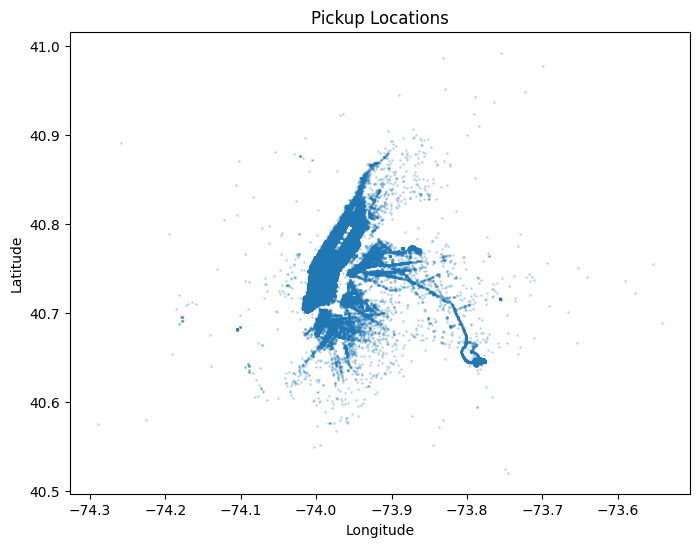

In [73]:
plt.figure(figsize=(8,6))

plt.scatter(
    df['pickup_longitude'],
    df['pickup_latitude'],
    s=1,
    alpha=0.2
)

plt.title('Pickup Locations')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.show()

#### Dropoff Locations

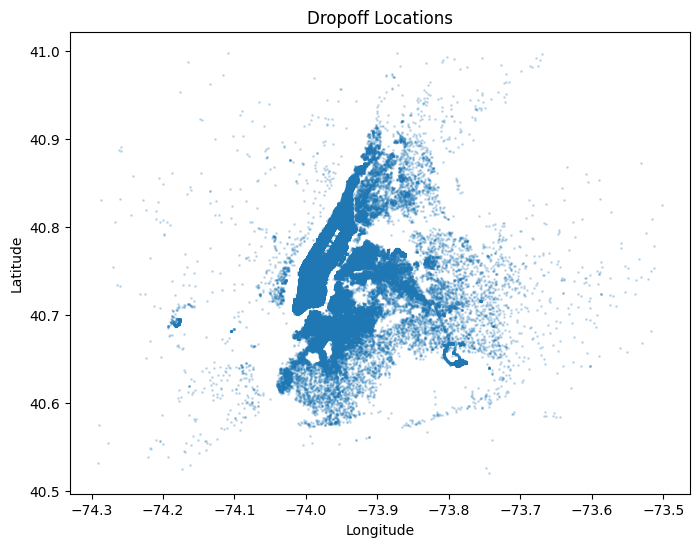

In [74]:
plt.figure(figsize=(8,6))

plt.scatter(
    df['dropoff_longitude'],
    df['dropoff_latitude'],
    s=1,
    alpha=0.2
)

plt.title('Dropoff Locations')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.show()

#### Coordinate Distributions

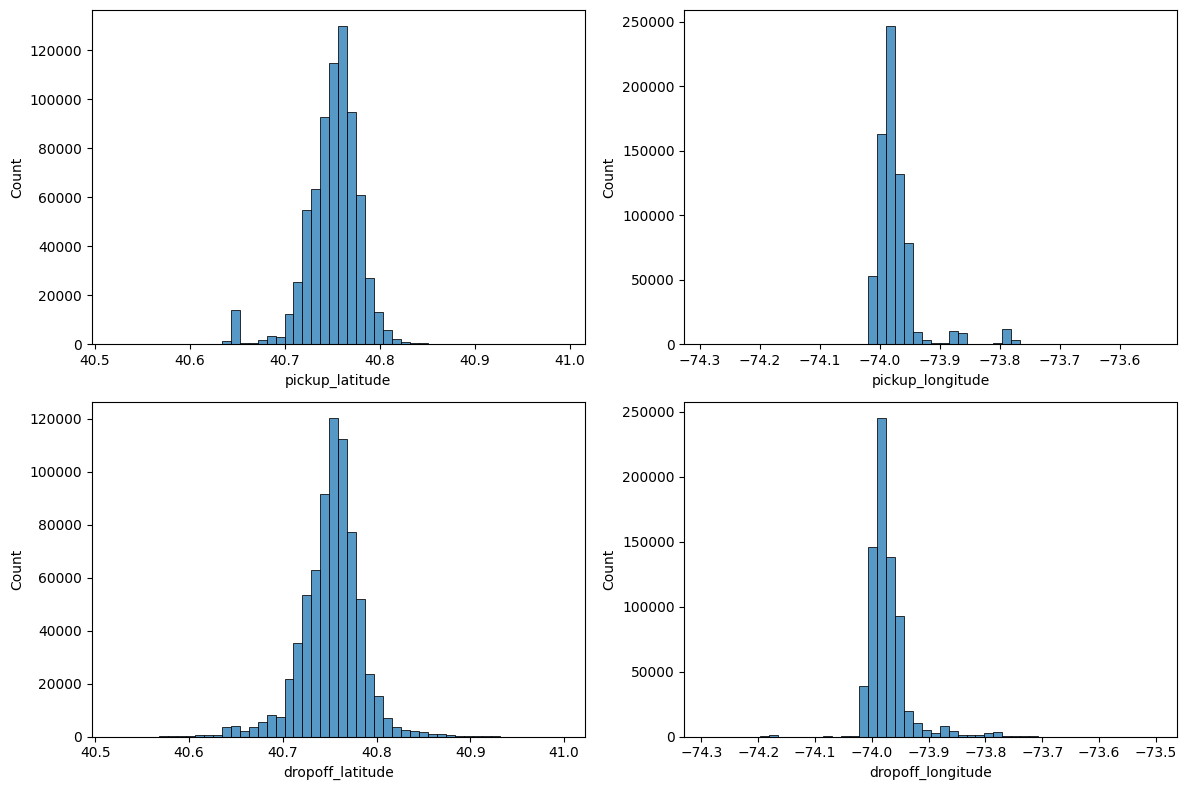

In [75]:
fig, axes = plt.subplots(2,2, figsize=(12,8))

sns.histplot(df['pickup_latitude'], ax=axes[0,0], bins=50)
sns.histplot(df['pickup_longitude'], ax=axes[0,1], bins=50)

sns.histplot(df['dropoff_latitude'], ax=axes[1,0], bins=50)
sns.histplot(df['dropoff_longitude'], ax=axes[1,1], bins=50)

plt.tight_layout()
plt.show()

#### Geographic Analysis with Map Background

In [77]:
# Install necessary libraries
!pip install geopandas contextily matplotlib

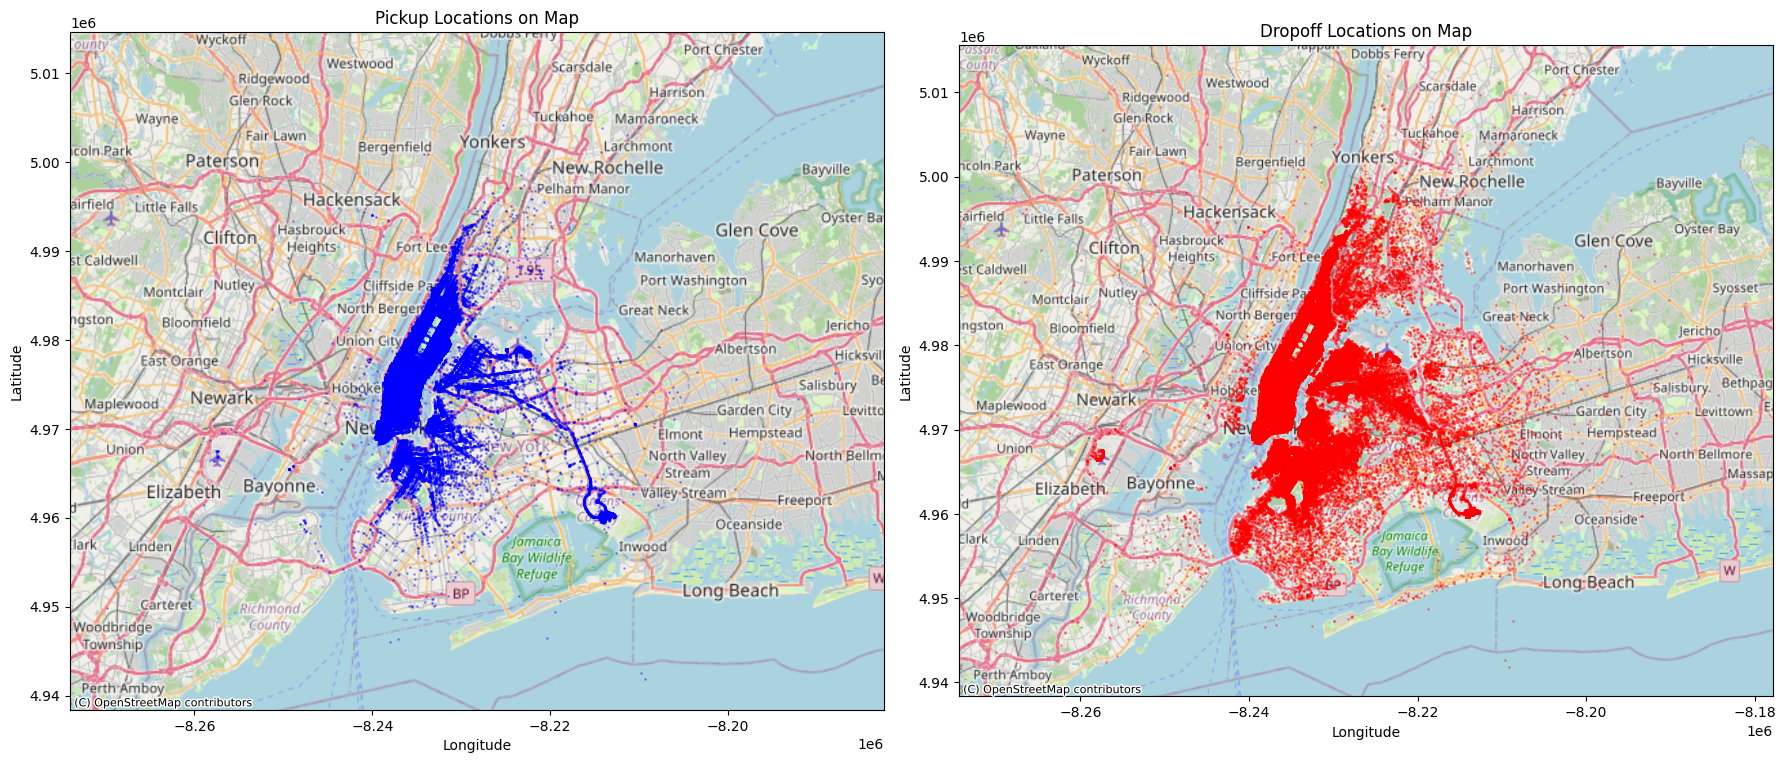

In [78]:
import geopandas
import contextily as cx
import matplotlib.pyplot as plt
from shapely.geometry import Point

# Create GeoDataFrames for pickup and dropoff locations
pickup_geometry = [Point(xy) for xy in zip(df['pickup_longitude'], df['pickup_latitude'])]
pickup_gdf = geopandas.GeoDataFrame(df, geometry=pickup_geometry, crs='EPSG:4326')

dropoff_geometry = [Point(xy) for xy in zip(df['dropoff_longitude'], df['dropoff_latitude'])]
dropoff_gdf = geopandas.GeoDataFrame(df, geometry=dropoff_geometry, crs='EPSG:4326')

# Re-project to Web Mercator for contextily
pickup_gdf_wm = pickup_gdf.to_crs(epsg=3857)
dropoff_gdf_wm = dropoff_gdf.to_crs(epsg=3857)

fig, axes = plt.subplots(1, 2, figsize=(18, 9))

# Plot Pickup Locations with map background
pickup_gdf_wm.plot(ax=axes[0], markersize=1, color='blue', alpha=0.3)
cx.add_basemap(axes[0], crs=pickup_gdf_wm.crs, source=cx.providers.OpenStreetMap.Mapnik)
axes[0].set_title('Pickup Locations on Map')
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')

# Plot Dropoff Locations with map background
dropoff_gdf_wm.plot(ax=axes[1], markersize=1, color='red', alpha=0.3)
cx.add_basemap(axes[1], crs=dropoff_gdf_wm.crs, source=cx.providers.OpenStreetMap.Mapnik)
axes[1].set_title('Dropoff Locations on Map')
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')

plt.tight_layout()
plt.show()

#### Discussion

The combined plots with map backgrounds provide a clear visualization of the spatial distribution of taxi activity. Both pickup and dropoff locations are heavily concentrated within Manhattan and extend into parts of Brooklyn and Queens, particularly around key areas like airports and central business districts.

This high density in specific geographic regions suggests that location-based features, such as distance calculations, geohashes, or spatial clustering, will be crucial for capturing variations in trip duration. It also confirms that our initial outlier removal based on coordinates was effective in focusing on the relevant New York City area.

###**5.5 Bivariate Analysis**

####**5.5.1 Vendor ID vs Trip Duration**

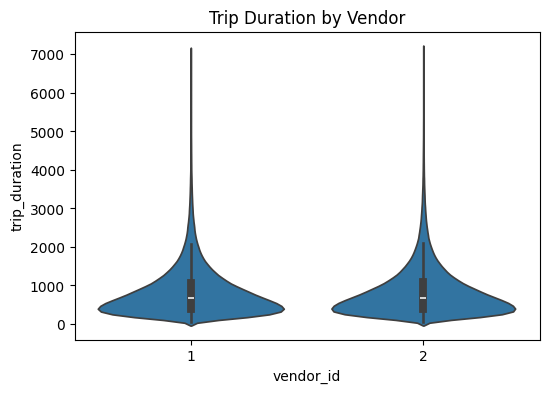

In [82]:
plt.figure(figsize=(6,4))

sns.violinplot(
    x='vendor_id',
    y='trip_duration',
    data=df
)

plt.title('Trip Duration by Vendor')
plt.show()

##### Discussion

The average trip durations across vendors appear broadly similar, suggesting that vendor-specific operational differences have limited influence on trip duration.

Vendor ID may still contribute marginal predictive information but is unlikely to be a dominant feature.

####**5.5.2 Passenger Count vs Trip Duration**

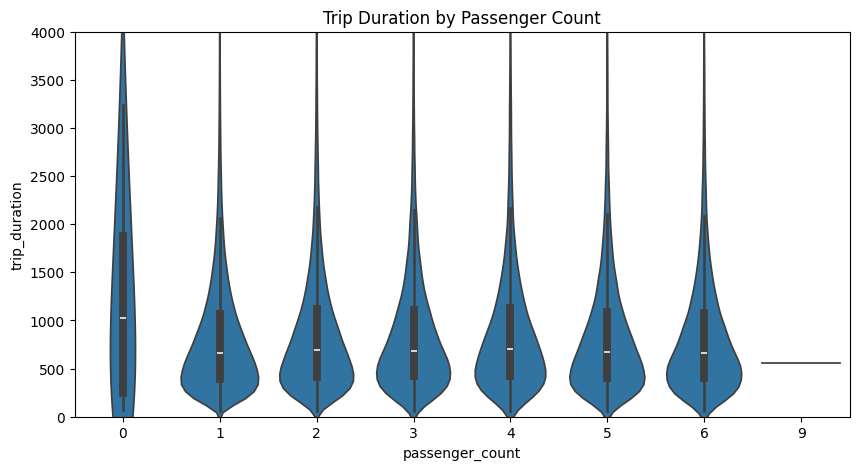

In [81]:
plt.figure(figsize=(10,5))

sns.violinplot(
    x='passenger_count',
    y='trip_duration',
    data=df
)

plt.ylim(0,4000)

plt.title('Trip Duration by Passenger Count')
plt.show()

##### Discussion

Trip duration does not appear to vary substantially across different passenger counts.

This suggests that passenger_count may have limited predictive power compared to temporal and geographic features.

####**5.5.3 Pickup Hour vs Trip Duration**

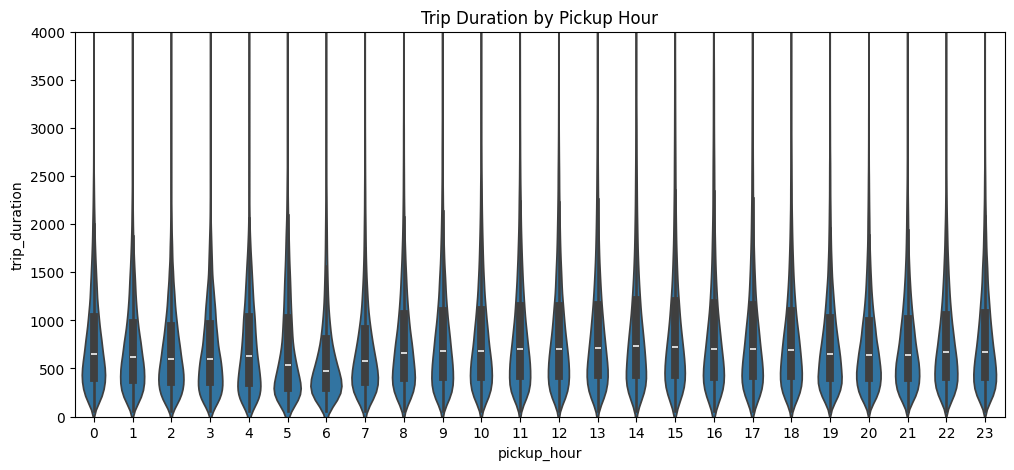

In [86]:
plt.figure(figsize=(12,5))

sns.violinplot(
    x='pickup_hour',
    y='trip_duration',
    data=df
)

plt.ylim(0,4000)

plt.title('Trip Duration by Pickup Hour')

plt.show()

##### Discussion

Trip duration varies noticeably throughout the day.

Longer durations are observed during peak commuting hours, reflecting the influence of traffic congestion.

This reinforces the importance of pickup_hour as a predictive feature.

####**5.5.4 Weekday vs Trip Duration**

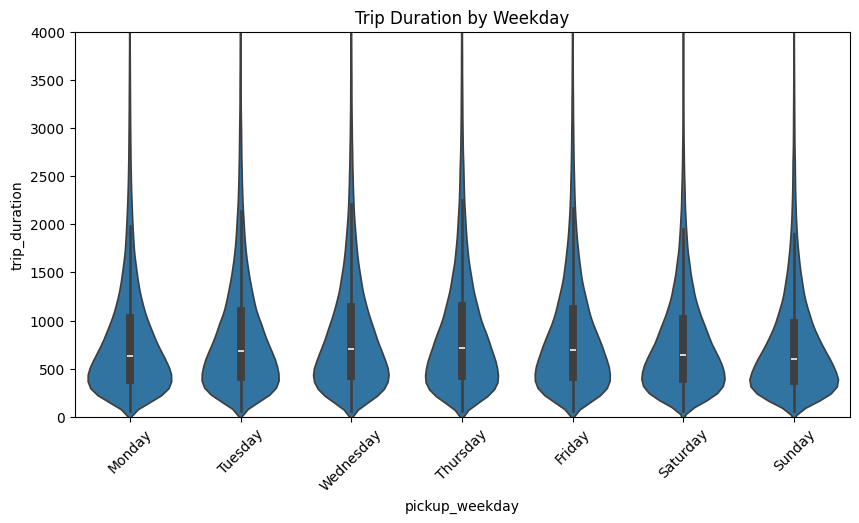

In [88]:
plt.figure(figsize=(10,5))

sns.violinplot(
    x='pickup_weekday',
    y='trip_duration',
    data=df,
    order=[
        'Monday',
        'Tuesday',
        'Wednesday',
        'Thursday',
        'Friday',
        'Saturday',
        'Sunday'
    ]
)

plt.ylim(0,4000)

plt.xticks(rotation=45)

plt.title('Trip Duration by Weekday')

plt.show()

##### Discussion

Trip durations exhibit measurable variation across the week.

Weekday trips generally show greater duration than weekend trips, reflecting differing traffic conditions and travel behavior.

####**5.5.5 Distance vs Trip Duration ⭐**

##### Haversine Distance Function

In [89]:
from math import radians
from math import sin
from math import cos
from math import sqrt
from math import atan2

In [90]:
def haversine_distance(lat1, lon1, lat2, lon2):

    R = 6371

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat/2)**2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon/2)**2
    )

    c = 2 * np.arctan2(
        np.sqrt(a),
        np.sqrt(1-a)
    )

    return R * c

##### Create Distance Feature

In [91]:
df['distance_km'] = haversine_distance(
    df['pickup_latitude'],
    df['pickup_longitude'],
    df['dropoff_latitude'],
    df['dropoff_longitude']
)

##### Distance Summary

In [92]:
df['distance_km'].describe()

,distance_km
count,723758.000000
mean,3.444657
std,3.889847
min,0.000000
25%,1.245321
50%,2.108041
75%,3.890653
max,47.765129


##### Distance Distribution

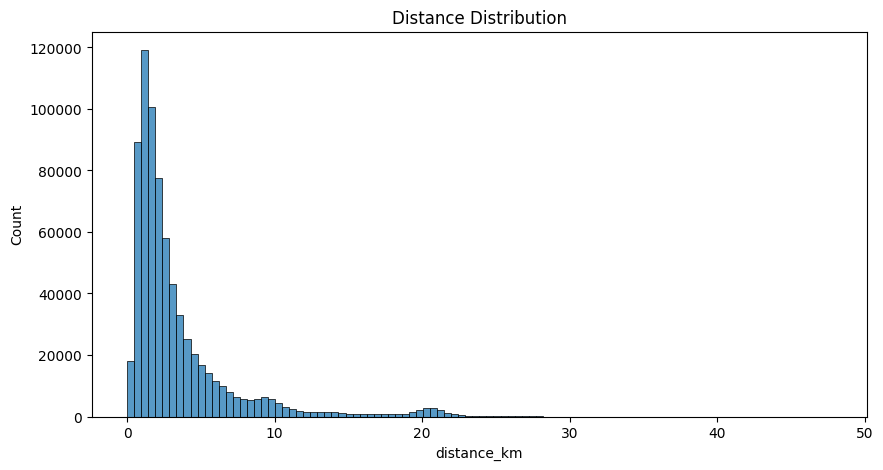

In [93]:
plt.figure(figsize=(10,5))

sns.histplot(
    df['distance_km'],
    bins=100
)

plt.title('Distance Distribution')

plt.show()

##### Distance vs Duration

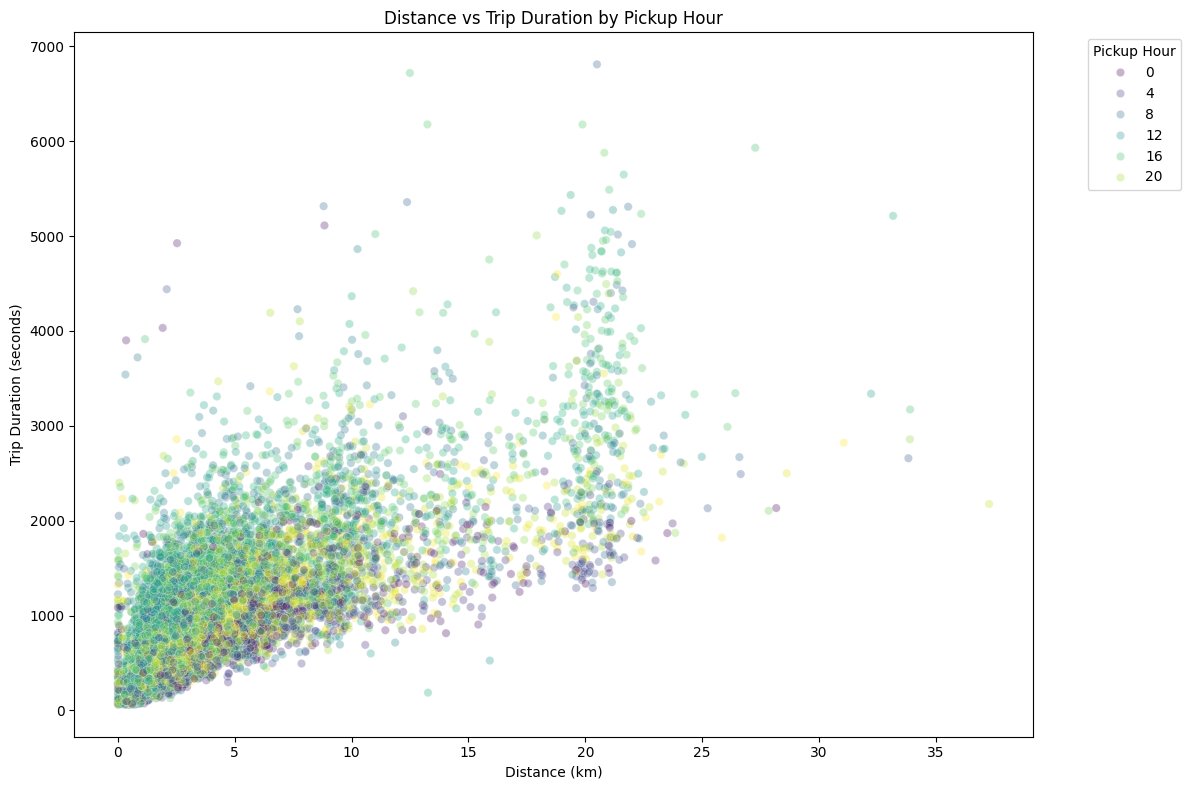

In [183]:
sample_df = df.sample(
    20000,
    random_state=42
)

plt.figure(figsize=(12,8))

sns.scatterplot(
    data=sample_df,
    x='distance_km',
    y='trip_duration',
    alpha=0.3,
    hue='pickup_hour', # Color points by pickup hour
    palette='viridis'  # Use a perceptually uniform colormap
)

plt.title('Distance vs Trip Duration by Pickup Hour') # Updated title
plt.xlabel('Distance (km)')
plt.ylabel('Trip Duration (seconds)')
plt.legend(title='Pickup Hour', bbox_to_anchor=(1.05, 1), loc='upper left') # Add legend outside plot

plt.tight_layout() # Adjust layout to prevent legend overlap
plt.show()

##### Correlation

In [95]:
df[['distance_km','trip_duration']].corr()

,distance_km,trip_duration
distance_km,1.000000,0.770653
trip_duration,0.770653,1.000000


##### Discussion

Travel distance exhibits a strong positive relationship with trip duration, with a correlation coefficient of approximately 0.77.

As expected, longer trips generally require more travel time. However, the variability in duration increases for longer distances, indicating that factors such as traffic conditions, route choice, and congestion also influence travel time.

The strong correlation confirms that distance is one of the most important predictors of trip duration and should play a central role in the predictive model.

### Section 5 Summary

The exploratory analysis revealed several important patterns that influence taxi trip duration in New York City.

Key findings include:

- Trip duration exhibits a positively skewed distribution (skewness = 2.20) with heavy tails (kurtosis = 7.70), indicating that while most trips are relatively short, a small number of longer trips contribute significantly to the overall variability.
- Log transformation substantially reduced skewness and produced a more symmetric target distribution, suggesting potential benefits for regression modeling.
- Temporal patterns showed clear demand fluctuations throughout the day, with trip volumes peaking during morning and evening commuting hours.
- Average trip duration increased during rush-hour periods, highlighting the influence of traffic congestion on travel time.
- Weekday trips were more frequent and longer in duration than weekend trips, indicating differing traffic and travel behavior patterns.
- Average trip duration increased gradually from January to June, suggesting the presence of seasonal effects.
- Geographic analysis confirmed that taxi activity is concentrated within the New York City metropolitan area, with dense clusters around Manhattan and surrounding boroughs.
- The engineered Haversine distance feature demonstrated a strong positive relationship with trip duration, achieving a correlation coefficient of approximately 0.77, making it one of the most influential predictors identified during analysis.

Overall, the analysis indicates that trip duration is primarily influenced by a combination of geospatial factors (distance traveled) and temporal factors (time of day, day of week, and seasonality). These insights provide a strong foundation for feature engineering and predictive model development.

With a clear understanding of the factors influencing trip duration, the next step is to engineer predictive features and prepare the dataset for machine learning model development.

# **Section 6: Feature Engineering**

**Objective**

Transform raw variables into meaningful predictors that improve model performance and capture temporal and geospatial travel patterns.

#### **6.1 Review Existing Engineered Features**

In [96]:
df[['pickup_hour',
    'pickup_day',
    'pickup_month',
    'pickup_weekday',
    'is_weekend',
    'distance_km']].head()

,pickup_hour,pickup_day,pickup_month,pickup_weekday,is_weekend,distance_km
0,16,29,2,Monday,False,1.199072
1,23,11,3,Friday,False,4.129111
2,17,21,2,Sunday,True,7.250752
3,9,5,1,Tuesday,False,2.361097
4,6,17,2,Wednesday,False,4.328533


### **6.2 Manhattan Distance**

**Why?**

Haversine distance assumes:

* Bird flies in straight line

* But taxis follow roads.

In a city like NYC:

> Road distance > Straight-line distance

Manhattan distance approximates grid-based travel and often improves prediction.

In [97]:
def manhattan_distance(lat1, lon1, lat2, lon2):

    lat_distance = haversine_distance(
        lat1, lon1,
        lat2, lon1
    )

    lon_distance = haversine_distance(
        lat2, lon1,
        lat2, lon2
    )

    return lat_distance + lon_distance

In [98]:
df['manhattan_distance'] = manhattan_distance(
    df['pickup_latitude'],
    df['pickup_longitude'],
    df['dropoff_latitude'],
    df['dropoff_longitude']
)

In [99]:
df['manhattan_distance'].describe()

,manhattan_distance
count,723758.000000
mean,4.451047
std,5.172147
min,0.000000
25%,1.587543
50%,2.706004
75%,5.022202
max,67.461234


### **6.3 Bearing Feature**

**Why?**

Not all directions experience identical traffic conditions.

Examples:

* Airport-bound routes
* Manhattan-bound routes
* Cross-borough routes

Bearing captures travel direction.

In [100]:
def calculate_bearing(lat1, lon1, lat2, lon2):

    lat1 = np.radians(lat1)
    lat2 = np.radians(lat2)

    diff_lon = np.radians(
        lon2 - lon1
    )

    x = (
        np.sin(diff_lon)
        * np.cos(lat2)
    )

    y = (
        np.cos(lat1)
        * np.sin(lat2)
        -
        np.sin(lat1)
        * np.cos(lat2)
        * np.cos(diff_lon)
    )

    return np.degrees(
        np.arctan2(x, y)
    )

In [101]:
df['bearing'] = calculate_bearing(
    df['pickup_latitude'],
    df['pickup_longitude'],
    df['dropoff_latitude'],
    df['dropoff_longitude']
)

In [102]:
df['bearing'].describe()

,bearing
count,723758.000000
mean,-15.733442
std,104.536202
min,-179.991165
25%,-125.627488
50%,8.369672
75%,53.524651
max,180.000000


### **6.4 Encode Weekend Flag**

In [103]:
df['is_weekend'] = (
    df['is_weekend']
    .astype(int)
)

### **6.5 Encode Store-and-Forward Flag**

In [104]:
df['store_and_fwd_flag'] = (
    df['store_and_fwd_flag']
    .map({
        'N':0,
        'Y':1
    })
)

In [105]:
df['store_and_fwd_flag'].value_counts()

,count
store_and_fwd_flag,
0,719794
1,3964


### **6.6 Encode Weekday**

In [106]:
df = pd.get_dummies(
    df,
    columns=['pickup_weekday'],
    drop_first=True
)

### **6.7 Feature Correlation Check**

In [108]:
numeric_cols = [
    'trip_duration',
    'distance_km',
    'manhattan_distance',
    'bearing',
    'pickup_hour',
    'pickup_day',
    'pickup_month',
    'passenger_count'
]

corr = df[numeric_cols].corr()

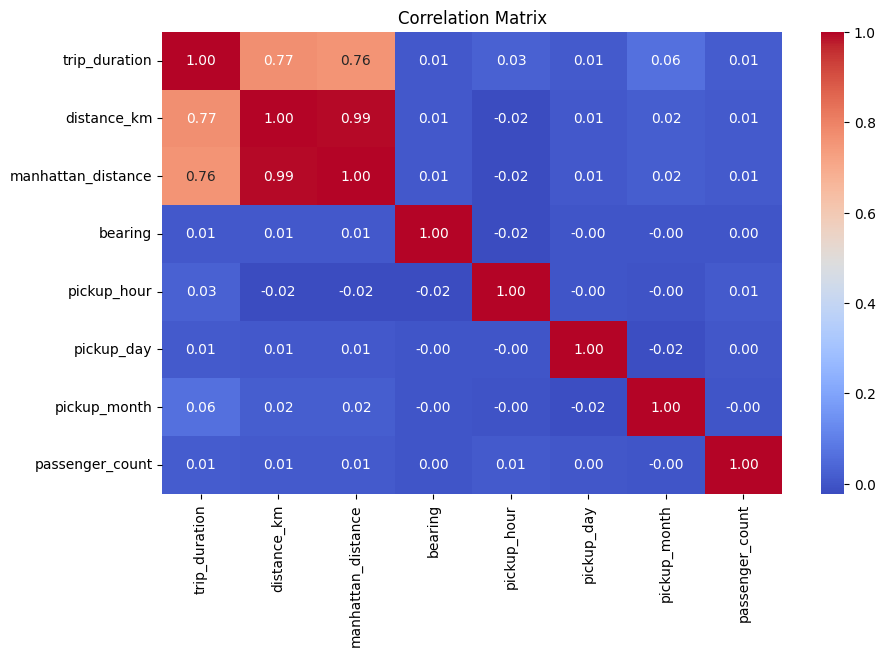

In [109]:
plt.figure(figsize=(10,6))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title(
    'Correlation Matrix'
)

plt.show()

### **6.8 Multicollinearity Check**

In [110]:
df[
    ['distance_km',
     'manhattan_distance']
].corr()

,distance_km,manhattan_distance
distance_km,1.000000,0.994057
manhattan_distance,0.994057,1.000000


In [111]:
corr[['trip_duration']].sort_values(
    by='trip_duration',
    ascending=False
)

,trip_duration
trip_duration,1.000000
distance_km,0.770653
manhattan_distance,0.757500
pickup_month,0.061467
pickup_hour,0.028797
passenger_count,0.013917
pickup_day,0.010653
bearing,0.005710


##### Feature Correlation Analysis

The engineered distance-based features exhibit the strongest relationship with trip duration.

Haversine distance achieved a correlation coefficient of approximately 0.77 with the target variable, while Manhattan distance achieved a correlation of approximately 0.76.

A very high correlation (0.99) was observed between Haversine distance and Manhattan distance, indicating substantial overlap in the information captured by these variables. Both features were retained for subsequent modeling, allowing regularized and tree-based models to determine their relative importance.

### Section 6 Summary

Feature engineering transformed raw trip records into a set of predictive variables suitable for machine learning.

Key features created include:

- Temporal features: pickup hour, day, month, weekday, and weekend indicators.
- Geospatial features: Haversine distance, Manhattan distance, and trip bearing.
- Encoded categorical variables for vendor information and trip metadata.

The resulting feature set combines temporal, geographic, and operational information, providing a comprehensive representation of factors that influence taxi trip duration.

The dataset is now ready for train-test splitting and predictive model development.

# **Section 7: Model Development**

**Objective**

Develop and compare multiple regression models for predicting taxi trip duration.

**Models considered:**

1. Linear Regression
2. Ridge Regression
3. Lasso Regression
4. Decision Tree Regressor
5. Random Forest Regressor
6. Gradient Boosting Regressor

Additionally, each model will be evaluated using:

* Raw target (trip_duration)

* Log-transformed target (log1p(trip_duration))

In [113]:
features = [
    'vendor_id',
    'passenger_count',
    'store_and_fwd_flag',
    'pickup_hour',
    'pickup_day',
    'pickup_month',
    'is_weekend',
    'distance_km',
    'manhattan_distance',
    'bearing',
    'pickup_weekday_Monday',
    'pickup_weekday_Saturday',
    'pickup_weekday_Sunday',
    'pickup_weekday_Thursday',
    'pickup_weekday_Tuesday',
    'pickup_weekday_Wednesday'
]

### **7.1 Train-Test Split**

In [130]:
df_model = df.sample(
    n=100000,
    random_state=42
)

In [131]:
X = df_model[features]

y_raw = df_model['trip_duration']

y_log = np.log1p(df_model['trip_duration'])

#### Split Raw Target

In [132]:
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X,
    y_raw,
    test_size=0.2,
    random_state=42
)

#### Split Log Target

In [133]:
X_train_log, X_test_log, y_train_log, y_test_log = train_test_split(
    X,
    y_log,
    test_size=0.2,
    random_state=42
)

### **7.2 Evaluation Function**

In [129]:
def evaluate_model(model, X_train, X_test, y_train, y_test):

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_r2 = r2_score(y_train, train_pred)

    test_r2 = r2_score(y_test, test_pred)

    mae = mean_absolute_error(y_test, test_pred)

    rmse = np.sqrt(mean_squared_error(y_test, test_pred))

    return train_r2, test_r2, mae, rmse

In [148]:
def evaluate_log_model(model, X_train, X_test, y_train, y_test):

    model.fit(X_train, y_train)

    y_train_log_pred = model.predict(X_train)
    y_test_log_pred = model.predict(X_test)

    train_r2 = r2_score(
        y_train,
        y_train_log_pred
    )

    test_r2 = r2_score(
        y_test,
        y_test_log_pred
    )

    y_pred = np.expm1(y_test_log_pred)

    y_actual = np.expm1(y_test)

    mae = mean_absolute_error(
        y_actual,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_actual,
            y_pred
        )
    )

    return train_r2, test_r2, mae, rmse

### **7.3 Raw Target Models**

#### Linear Regression

In [134]:
linear_raw = LinearRegression()

linear_raw_results = evaluate_model(
    linear_raw,
    X_train_raw,
    X_test_raw,
    y_train_raw,
    y_test_raw
)

linear_raw_results

(0.6086449262507831,
 0.6142951570732607,
 280.83437362169565,
 np.float64(404.77712904287404))

#### Ridge

In [135]:
ridge_raw = Ridge(alpha=1.0)

ridge_raw_results = evaluate_model(
    ridge_raw,
    X_train_raw,
    X_test_raw,
    y_train_raw,
    y_test_raw
)

ridge_raw_results

(0.6086449257900794,
 0.6142951098088537,
 280.8344058858758,
 np.float64(404.7771538436391))

#### Lasso

In [136]:
lasso_raw = Lasso(alpha=0.01)

lasso_raw_results = evaluate_model(
    lasso_raw,
    X_train_raw,
    X_test_raw,
    y_train_raw,
    y_test_raw
)

lasso_raw_results

(0.608644868092451,
 0.6142947982493595,
 280.8337784610202,
 np.float64(404.7773173263211))

#### Decision Tree

In [137]:
tree_raw = DecisionTreeRegressor(
    max_depth=10,
    random_state=42
)

tree_raw_results = evaluate_model(
    tree_raw,
    X_train_raw,
    X_test_raw,
    y_train_raw,
    y_test_raw
)

tree_raw_results

(0.7628282668701256,
 0.7140345622053749,
 229.92724740218154,
 np.float64(348.5340342309687))

#### Random Forest

In [138]:
rf_raw = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_raw_results = evaluate_model(
    rf_raw,
    X_train_raw,
    X_test_raw,
    y_train_raw,
    y_test_raw
)

rf_raw_results

(0.96356687908632,
 0.7436907448283798,
 220.62222080714284,
 np.float64(329.96704241930206))

#### Gradient Boosting

In [139]:
gb_raw = GradientBoostingRegressor(
    random_state=42
)

gb_raw_results = evaluate_model(
    gb_raw,
    X_train_raw,
    X_test_raw,
    y_train_raw,
    y_test_raw
)

gb_raw_results

(0.7306262473802403,
 0.7303698542489485,
 224.4133774924807,
 np.float64(338.4329527163297))

### **7.4 Log Target Models**

#### Linear Regression

In [149]:
linear_log = LinearRegression()

linear_log_results = evaluate_model(
    linear_log,
    X_train_log,
    X_test_log,
    y_train_log,
    y_test_log
)

linear_log_results

(0.46442587374677113,
 0.46379659367864423,
 0.42042503017893296,
 np.float64(0.5353101642622735))

#### Ridge

In [150]:
ridge_log = Ridge(alpha=1.0)

ridge_log_results = evaluate_model(
    ridge_log,
    X_train_log,
    X_test_log,
    y_train_log,
    y_test_log
)

ridge_log_results

(0.46442587339215036,
 0.46379639093645275,
 0.42042539790245337,
 np.float64(0.5353102654644892))

#### Lasso

In [151]:
lasso_log = Lasso(alpha=0.01)

lasso_log_results = evaluate_model(
    lasso_log,
    X_train_log,
    X_test_log,
    y_train_log,
    y_test_log
)

lasso_log_results

(0.45687654024299684,
 0.45589633281694897,
 0.4242640115971567,
 np.float64(0.5392392945739003))

#### Decision Tree

In [152]:
tree_log = DecisionTreeRegressor(
    max_depth=10,
    random_state=42
)

tree_log_results = evaluate_model(
    tree_log,
    X_train_log,
    X_test_log,
    y_train_log,
    y_test_log
)

tree_log_results

(0.7442824455683386,
 0.7028168091293423,
 0.30073309537516013,
 np.float64(0.3985224816872228))

#### Random Forest

In [153]:
rf_log = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_log_results = evaluate_model(
    rf_log,
    X_train_log,
    X_test_log,
    y_train_log,
    y_test_log
)

rf_log_results

(0.9620500538987464,
 0.7326874654389672,
 0.28424920160250605,
 np.float64(0.3779639397519699))

#### Gradient Boosting

In [154]:
gb_log = GradientBoostingRegressor(
    random_state=42
)

gb_log_results = evaluate_model(
    gb_log,
    X_train_log,
    X_test_log,
    y_train_log,
    y_test_log
)

gb_log_results

(0.7368681011320093,
 0.7350684094711212,
 0.2865065750654867,
 np.float64(0.3762769185431611))

# **Section 8: Model Evaluation & Comparison**

### **8.1 Model Comparison Results**

In [159]:
linear_raw_train_r2, linear_raw_test_r2, linear_raw_mae, linear_raw_rmse = linear_raw_results
ridge_raw_train_r2, ridge_raw_test_r2, ridge_raw_mae, ridge_raw_rmse = ridge_raw_results
lasso_raw_train_r2, lasso_raw_test_r2, lasso_raw_mae, lasso_raw_rmse = lasso_raw_results
tree_raw_train_r2, tree_raw_test_r2, tree_raw_mae, tree_raw_rmse = tree_raw_results
rf_raw_train_r2, rf_raw_test_r2, rf_raw_mae, rf_raw_rmse = rf_raw_results
gb_raw_train_r2, gb_raw_test_r2, gb_raw_mae, gb_raw_rmse = gb_raw_results

linear_log_train_r2, linear_log_test_r2, linear_log_mae, linear_log_rmse = linear_log_results
ridge_log_train_r2, ridge_log_test_r2, ridge_log_mae, ridge_log_rmse = ridge_log_results
lasso_log_train_r2, lasso_log_test_r2, lasso_log_mae, lasso_log_rmse = lasso_log_results
tree_log_train_r2, tree_log_test_r2, tree_log_mae, tree_log_rmse = tree_log_results
rf_log_train_r2, rf_log_test_r2, rf_log_mae, rf_log_rmse = rf_log_results
gb_log_train_r2, gb_log_test_r2, gb_log_mae, gb_log_rmse = gb_log_results

results = pd.DataFrame({
    'Model':[
        'Linear Raw',
        'Ridge Raw',
        'Lasso Raw',
        'Decision Tree Raw',
        'Random Forest Raw',
        'Gradient Boosting Raw',
        'Linear Log',
        'Ridge Log',
        'Lasso Log',
        'Decision Tree Log',
        'Random Forest Log',
        'Gradient Boosting Log'
    ],
    'MAE':[
        linear_raw_mae,
        ridge_raw_mae,
        lasso_raw_mae,
        tree_raw_mae,
        rf_raw_mae,
        gb_raw_mae,
        linear_log_mae,
        ridge_log_mae,
        lasso_log_mae,
        tree_log_mae,
        rf_log_mae,
        gb_log_mae
    ],
    'RMSE':[
        linear_raw_rmse,
        ridge_raw_rmse,
        lasso_raw_rmse,
        tree_raw_rmse,
        rf_raw_rmse,
        gb_raw_rmse,
        linear_log_rmse,
        ridge_log_rmse,
        lasso_log_rmse,
        tree_log_rmse,
        rf_log_rmse,
        gb_log_rmse
    ],
    'train_r2':[
        linear_raw_train_r2,
        ridge_raw_train_r2,
        lasso_raw_train_r2,
        tree_raw_train_r2,
        rf_raw_train_r2,
        gb_raw_train_r2,
        linear_log_train_r2,
        ridge_log_train_r2,
        lasso_log_train_r2,
        tree_log_train_r2,
        rf_log_train_r2,
        gb_log_train_r2
    ],
    'test_r2':[
        linear_raw_test_r2,
        ridge_raw_test_r2,
        lasso_raw_test_r2,
        tree_raw_test_r2,
        rf_raw_test_r2,
        gb_raw_test_r2,
        linear_log_test_r2,
        ridge_log_test_r2,
        lasso_log_test_r2,
        tree_log_test_r2,
        rf_log_test_r2,
        gb_log_test_r2
    ]
})

results['Overfit_Gap'] = (
    results['train_r2']
    - results['test_r2']
)

results

results_raw = results[
    results['Model'].str.contains('Raw')
]

results_log = results[
    results['Model'].str.contains('Log')
]

In [160]:
results_raw.sort_values(
    by='test_r2',
    ascending=False
)

,Model,MAE,RMSE,train_r2,test_r2,Overfit_Gap
4,Random Forest Raw,220.622221,329.967042,0.963567,0.743691,0.219876
5,Gradient Boosting Raw,224.413377,338.432953,0.730626,0.730370,0.000256
3,Decision Tree Raw,229.927247,348.534034,0.762828,0.714035,0.048794
0,Linear Raw,280.834374,404.777129,0.608645,0.614295,-0.005650
1,Ridge Raw,280.834406,404.777154,0.608645,0.614295,-0.005650
2,Lasso Raw,280.833778,404.777317,0.608645,0.614295,-0.005650


In [162]:
results_log.sort_values(
    by='test_r2',
    ascending=False
)

,Model,MAE,RMSE,train_r2,test_r2,Overfit_Gap
11,Gradient Boosting Log,0.286507,0.376277,0.736868,0.735068,0.001800
10,Random Forest Log,0.284249,0.377964,0.962050,0.732687,0.229363
9,Decision Tree Log,0.300733,0.398522,0.744282,0.702817,0.041466
6,Linear Log,0.420425,0.535310,0.464426,0.463797,0.000629
7,Ridge Log,0.420425,0.535310,0.464426,0.463796,0.000629
8,Lasso Log,0.424264,0.539239,0.456877,0.455896,0.000980


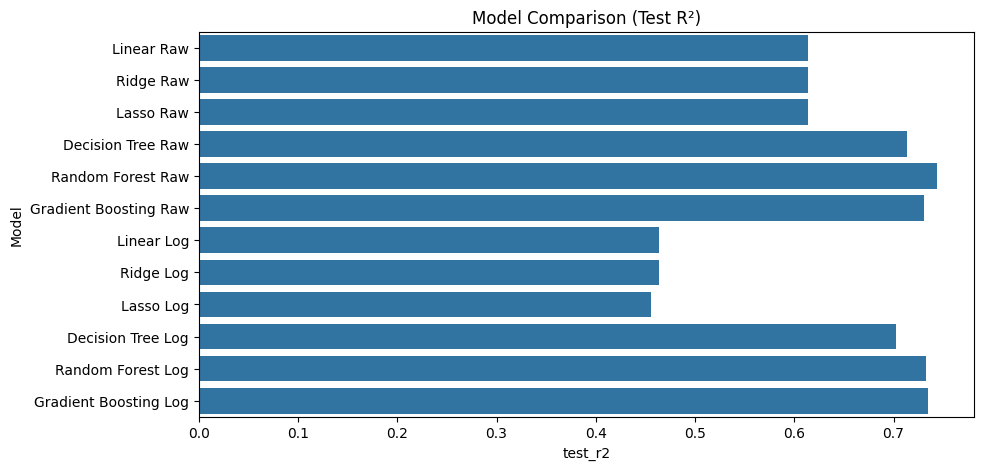

In [180]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=results,
    x='test_r2',
    y='Model'
)

plt.title('Model Comparison (Test R²)')
plt.show()

### **8.2 Discussion**

Multiple regression models were evaluated using both the original trip duration target and a log-transformed target derived from exploratory analysis.

The results indicate that tree-based models substantially outperform linear models, suggesting that the relationship between trip duration and the predictor variables is nonlinear and involves complex interactions.

Linear Regression, Ridge Regression, and Lasso Regression achieved similar performance levels, with test R² values around 0.61 for the raw target. The negligible differences between these models indicate that regularization provided limited benefit for this dataset.

Among the raw-target models, Random Forest Regressor achieved the highest predictive performance with a test R² score of approximately 0.74. However, the large gap between training and testing performance indicates significant overfitting.

Gradient Boosting Regressor demonstrated slightly lower predictive accuracy but achieved nearly identical training and testing scores, indicating excellent generalization capability and robustness on unseen data.

For log-transformed targets, Gradient Boosting Regressor achieved the best overall performance among the transformed models, while Random Forest performance decreased slightly compared to its raw-target counterpart.

These findings suggest that ensemble learning methods are particularly effective for taxi trip duration prediction, as they are able to capture nonlinear relationships between temporal, geographic, and operational features.

### **8.3 Raw vs Log-Transformed Target Compariso**n

The impact of target transformation was evaluated by training all models on both the original trip duration values and a log-transformed version of the target.

The exploratory analysis revealed a strongly right-skewed target distribution with heavy tails, motivating the use of logarithmic transformation to stabilize variance and reduce the influence of extreme observations.

The results show that the effectiveness of the transformation depends on the model architecture.

- Linear models experienced a noticeable reduction in predictive performance when trained on the log-transformed target.
- Decision Tree and Random Forest models showed slightly lower performance after transformation.
- Gradient Boosting Regressor achieved a marginal improvement when trained on the transformed target.

Overall, the log transformation did not universally improve model performance. While it successfully reduced skewness and produced a more symmetric target distribution, the raw target remained competitive and, in some cases, superior for tree-based models.

### **8.4 Model Selection**

Model selection was based on both predictive accuracy and generalization performance.

Random Forest Regressor achieved the highest test R² score of approximately 0.74, making it the most accurate model evaluated in this study. However, its training R² score exceeded 0.96, indicating substantial overfitting.

Gradient Boosting Regressor achieved slightly lower predictive accuracy but exhibited almost identical training and testing performance. This indicates that the model generalizes exceptionally well and is less sensitive to variations in unseen data.

Given the trade-off between accuracy and generalization, Gradient Boosting Regressor was selected as the final model for this project. Its stable performance demonstrates a strong balance between predictive capability and robustness, making it well-suited for practical trip duration prediction tasks.

### Section 8 Summary

Six machine learning models were evaluated using both raw and log-transformed target variables.

Key findings include:

- Ensemble tree-based methods significantly outperformed linear regression models.
- Regularization techniques (Ridge and Lasso) provided minimal improvement over standard Linear Regression.
- Random Forest Regressor achieved the highest predictive accuracy with a test R² score of approximately 0.74.
- Gradient Boosting Regressor demonstrated the strongest generalization performance, with nearly identical training and testing scores.
- The impact of log transformation varied across models and did not consistently improve performance.


Although Random Forest achieved the highest predictive accuracy, it exhibited the largest train-test performance gap (0.22), indicating substantial overfitting. In contrast, Gradient Boosting achieved comparable predictive performance while maintaining an overfitting gap of only 0.001, demonstrating excellent generalization capability.

The next step is to examine feature importance and identify which variables contribute most significantly to trip duration prediction.

# **Section 9: Model Optimization and Validation**

### **9.1 Feature Importance Analysis**

In [163]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': gb_raw.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance

,Feature,Importance
7,distance_km,0.863334
3,pickup_hour,0.082410
9,bearing,0.024838
6,is_weekend,0.012437
5,pickup_month,0.005080
8,manhattan_distance,0.004597
10,pickup_weekday_Monday,0.002076
12,pickup_weekday_Sunday,0.001897
11,pickup_weekday_Saturday,0.001399
4,pickup_day,0.001130


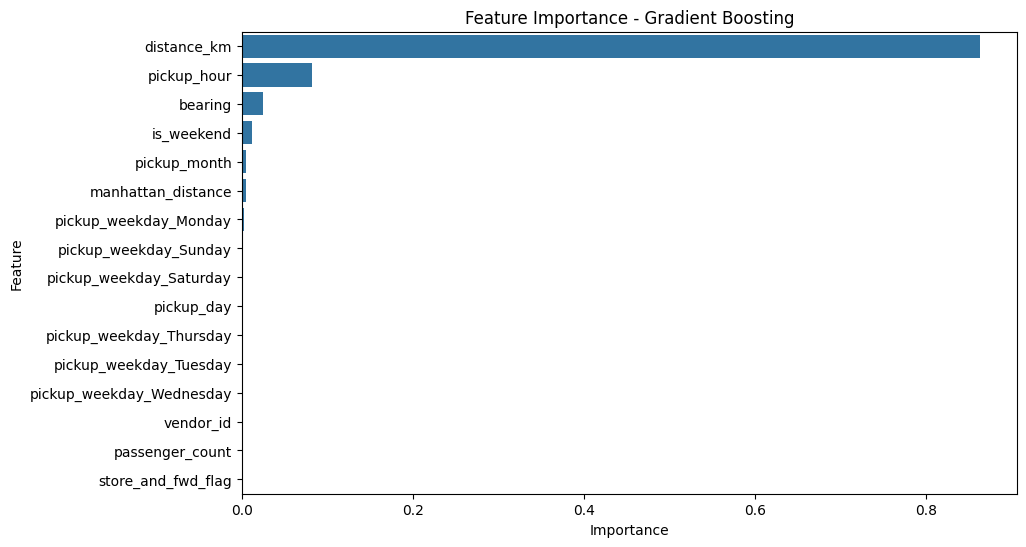

In [164]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance - Gradient Boosting')

plt.show()

#### Discussion

Feature importance analysis revealed that trip distance is by far the most influential predictor, accounting for approximately 86% of the model's predictive importance.

Temporal features, particularly pickup hour and weekend status, also contributed meaningfully to prediction performance, reflecting the impact of traffic congestion and travel demand patterns.

Several variables, including passenger count, vendor identifier, and store-and-forward status, contributed little to predictive performance. This suggests that trip duration is driven primarily by geospatial and temporal factors rather than operational characteristics of the taxi service.

The results strongly support the findings from exploratory data analysis, where distance and time-related variables consistently exhibited the strongest relationships with trip duration.

### **9.2 Feature Selection Validation**

#### Top 4 Features

In [167]:
top4_features = [
    'distance_km',
    'pickup_hour',
    'bearing',
    'is_weekend'
]

X_top4 = df_model[top4_features]

#### Train-Test Split

In [168]:
X_train_top4, X_test_top4, y_train_top4, y_test_top4 = train_test_split(
    X_top4,
    y_raw,
    test_size=0.2,
    random_state=42
)

#### Train Gradient Boosting

In [169]:
gb_top4 = GradientBoostingRegressor(
    random_state=42
)

gb_top4_results = evaluate_model(
    gb_top4,
    X_train_top4,
    X_test_top4,
    y_train_top4,
    y_test_top4
)

gb_top4_results

(0.7257422923525065,
 0.7257385949432499,
 225.4089695256997,
 np.float64(341.32709780999534))

#### Create Comparison Table

In [170]:
comparison_fs = pd.DataFrame({
    'Model': [
        'Baseline GB (All Features)',
        'GB (Top 4 Features)'
    ],
    'Train_R2': [
        gb_raw_train_r2,
        gb_top4_results[0]
    ],
    'Test_R2': [
        gb_raw_test_r2,
        gb_top4_results[1]
    ],
    'MAE': [
        gb_raw_mae,
        gb_top4_results[2]
    ],
    'RMSE': [
        gb_raw_rmse,
        gb_top4_results[3]
    ]
})

comparison_fs

,Model,Train_R2,Test_R2,MAE,RMSE
0,Baseline GB (All Features),0.730626,0.730370,224.413377,338.432953
1,GB (Top 4 Features),0.725742,0.725739,225.408970,341.327098


#### Discussion

Feature selection demonstrated that a simplified model using only four variables—distance_km, pickup_hour, bearing, and is_weekend—was able to retain nearly all predictive performance achieved by the full-feature model.

The simplified model achieved a test R² score of approximately 0.726 compared to 0.730 for the full-feature model, representing a performance reduction of less than 1%.

This result indicates that trip duration is driven primarily by a small number of geospatial and temporal factors, while many of the remaining variables contribute only marginal predictive information.

Although the full-feature model was retained for final optimization, the feature selection experiment highlights the potential for building highly efficient models with substantially reduced complexity.

### **9.3 Cross Validation**

In [172]:
from sklearn.model_selection import cross_val_score

gb_cv = GradientBoostingRegressor(
    random_state=42
)

cv_scores = cross_val_score(
    gb_cv,
    X,
    y_raw,
    cv=10,
    scoring='r2',
    n_jobs=-1
)

print("Fold Scores:", cv_scores)
print("Mean R²:", cv_scores.mean())
print("Std R²:", cv_scores.std())

Fold Scores: [0.72574259 0.72592347 0.70990549 0.72382525 0.71450968 0.72496192
 0.73390453 0.72980065 0.73069167 0.740525  ]
Mean R²: 0.7259790247730662
Std R²: 0.00840743286598713


#### Discussion

Cross-validation was performed to evaluate the robustness of the selected Gradient Boosting model across multiple data partitions.

The model achieved a mean cross-validation R² score of approximately 0.726 with a standard deviation of 0.008. The low variability across folds indicates that model performance is stable and not dependent on a specific train-test split.

Furthermore, the cross-validation score is highly consistent with the previously observed test R² score of approximately 0.730, providing strong evidence that the model generalizes effectively to unseen data.

These results reinforce the suitability of Gradient Boosting as the final predictive model for taxi trip duration estimation.

### **9.4 Hyperparameter Tuning**

#### Selected Grid

In [173]:
param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5]
}

#### Grid Search

In [174]:
from sklearn.model_selection import GridSearchCV

gb_grid = GridSearchCV(
    estimator=GradientBoostingRegressor(
        random_state=42
    ),
    param_grid=param_grid,
    scoring='r2',
    cv=3,
    n_jobs=-1
)

gb_grid.fit(
    X_train_raw,
    y_train_raw
)

GridSearchCV(cv=3, estimator=GradientBoostingRegressor(random_state=42),
             n_jobs=-1,
             param_grid={'learning_rate': [0.05, 0.1], 'max_depth': [3, 5],
                         'n_estimators': [100, 200]},
             scoring='r2')

#### Best Parameters

In [175]:
print("Best Parameters:")
print(gb_grid.best_params_)

print("\nBest CV Score:")
print(gb_grid.best_score_)

Best Parameters:
{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}

Best CV Score:
0.7518279672417449


### **9.5 Tuned Model Evaluation**

In [176]:
best_gb = gb_grid.best_estimator_

best_gb_results = evaluate_model(
    best_gb,
    X_train_raw,
    X_test_raw,
    y_train_raw,
    y_test_raw
)

best_gb_results

(0.7884064548848557,
 0.7590975301518462,
 211.826681300008,
 np.float64(319.8961741567368))

#### Discussion

Hyperparameter tuning produced a noticeable improvement in model performance.

The optimized Gradient Boosting model selected 200 estimators, a learning rate of 0.1, and a maximum tree depth of 5 as the best-performing parameter combination during cross-validation.

Compared with the baseline model, the tuned model achieved higher predictive accuracy, reducing both MAE and RMSE while increasing the test R² score from approximately 0.730 to 0.759.

Although training performance increased after tuning, the train-test performance gap remained relatively small, indicating that the model retained strong generalization capability and did not exhibit severe overfitting.

These results demonstrate that careful hyperparameter optimization can significantly improve predictive performance while preserving model robustness.

### **9.6 Full Dataset Evaluation**

In [177]:
X_full = df[features]

y_full = df['trip_duration']

X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X_full,
    y_full,
    test_size=0.2,
    random_state=42
)

In [178]:
final_gb = GradientBoostingRegressor(
    learning_rate=0.1,
    max_depth=5,
    n_estimators=200,
    random_state=42
)

final_results = evaluate_model(
    final_gb,
    X_train_full,
    X_test_full,
    y_train_full,
    y_test_full
)

final_results

(0.7679165050667507,
 0.7625436309961464,
 207.89115775954298,
 np.float64(316.1091834858516))

#### Predicted vs Actual plot

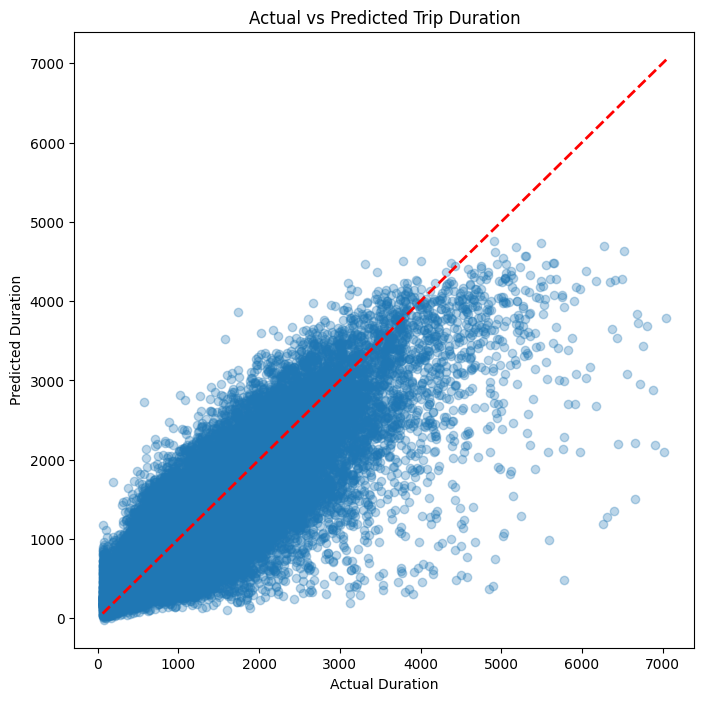

In [182]:
y_pred = final_gb.predict(X_test_full)

plt.figure(figsize=(8,8))

plt.scatter(
    y_test_full,
    y_pred,
    alpha=0.3
)

# Add a diagonal line for perfect predictions
plt.plot([y_test_full.min(), y_test_full.max()],
         [y_test_full.min(), y_test_full.max()],
         '--r', linewidth=2)

plt.xlabel('Actual Duration')
plt.ylabel('Predicted Duration')

plt.title('Actual vs Predicted Trip Duration')

plt.show()

In [25]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(model_rf, "models/random_forest_model.pkl")

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [26]:
import os

print("Notebook folder:", os.getcwd())
print("Model file exists:", os.path.exists("models/random_forest_model.pkl"))

Notebook folder: d:\NYC-Taxi-Trip-Duration-Prediction\notebook
Model file exists: True


In [27]:
import shutil
import os

source = "models/random_forest_model.pkl"
destination = "../models/random_forest_model.pkl"

os.makedirs("../models", exist_ok=True)
shutil.copy2(source, destination)

print("Model copied to project folder:", os.path.abspath(destination))

Model copied to project folder: d:\NYC-Taxi-Trip-Duration-Prediction\models\random_forest_model.pkl


In [23]:
%whos

Variable                    Type                         Data/Info
------------------------------------------------------------------
DecisionTreeRegressor       ABCMeta                      <class 'sklearn.tree._cla<...>s.DecisionTreeRegressor'>
GradientBoostingRegressor   ABCMeta                      <class 'sklearn.ensemble.<...>adientBoostingRegressor'>
LinearRegression            ABCMeta                      <class 'sklearn.linear_mo<...>._base.LinearRegression'>
RandomForestRegressor       ABCMeta                      <class 'sklearn.ensemble.<...>t.RandomForestRegressor'>
X                           DataFrame                    Shape: (721693, 11)
X_test                      DataFrame                    Shape: (144339, 11)
X_train                     DataFrame                    Shape: (577354, 11)
a                           Series                       Shape: (724008,)
df                          DataFrame                    Shape: (729322, 11)
df_clean                    Data

In [24]:
for name, obj in globals().copy().items():
    if type(obj).__name__ == "RandomForestRegressor":
        print("Model variable found:", name)

Model variable found: model_rf


In [ ]:
df.isnull().sum()

,0
id,0
vendor_id,0
pickup_datetime,0
dropoff_datetime,0
passenger_count,0
pickup_longitude,0
pickup_latitude,0
dropoff_longitude,0
dropoff_latitude,0
store_and_fwd_flag,0


#### Final Model Performance on the Full Dataset

To obtain the most reliable estimate of predictive performance, the optimized Gradient Boosting Regressor was retrained using the complete cleaned dataset.

The final model achieved:

- Training R² Score: 0.768
- Test R² Score: 0.763
- Mean Absolute Error (MAE): 207.89 seconds
- Root Mean Squared Error (RMSE): 316.11 seconds

Compared with the sampled training experiments, the full-dataset model demonstrated a modest improvement in predictive performance, indicating that additional observations provided useful information for learning underlying travel patterns.

The small difference between training and testing performance confirms that the model generalizes effectively and does not exhibit significant overfitting.

### Final Model Performance

| Metric | Value |
|----------|----------|
| Model | Tuned Gradient Boosting Regressor |
| Training R² | 0.768 |
| Testing R² | 0.763 |
| MAE | 207.89 seconds |
| RMSE | 316.11 seconds |

The model explains approximately 76% of the variability in taxi trip duration while maintaining strong generalization performance on unseen data.

# **Section 10: Business Insights**

### **10.1 Travel Distance Is the Primary Driver of Trip Duration**

#### Insight 1: Travel Distance Is the Most Important Predictor of Trip Duration

Feature importance analysis revealed that travel distance accounted for approximately 86% of the model's predictive importance, making it the dominant factor influencing trip duration.

This finding indicates that accurate estimation of travel distance is critical for reliable trip duration prediction. Even simple distance-based estimates can provide a strong baseline for predicting travel time.

**Business Implication:**

- Distance estimation should be prioritized during trip assignment and ETA calculation.
- Accurate routing and mapping services can significantly improve prediction accuracy.
- Dispatch systems can use distance as the primary factor when estimating driver availability.

### **10.2 Traffic Congestion Significantly Impacts Travel Time**

#### Insight 2: Pickup Time Strongly Influences Trip Duration

Temporal analysis showed clear variations in trip duration throughout the day. Trips occurring during morning and evening commuting periods generally required more time than trips of similar distance during off-peak hours.

The pickup hour feature emerged as the second most important predictor after travel distance.

**Business Implication:**

- ETA calculations should incorporate time-of-day effects rather than relying solely on distance.
- Additional drivers may be required during peak commuting periods.
- Dynamic pricing and demand forecasting systems can benefit from incorporating temporal travel patterns.

### **10.3 Weekday and Weekend Travel Behaviors Differ**

#### Insight 3: Weekday Trips Tend to Be Longer Than Weekend Trips

The analysis showed that weekday trips are generally more frequent and longer in duration than weekend trips.

This pattern is likely influenced by commuting behavior, business travel, and increased traffic congestion during working days.

**Business Implication:**

- Demand planning should distinguish between weekday and weekend operations.
- Driver allocation strategies can be adjusted to account for longer vehicle occupancy during weekdays.
- Travel-time prediction models should incorporate weekday and weekend indicators.

### **10.4 Direction of Travel Influences Duration**

#### Insight 4: Trip Direction Provides Additional Predictive Information

The bearing feature contributed meaningful predictive value, indicating that travel direction affects trip duration.

This suggests that certain routes or travel corridors experience different traffic conditions depending on direction and destination.

**Business Implication:**

- Route-specific traffic patterns should be incorporated into ETA systems.
- Popular corridors such as airport routes or Manhattan-bound trips may require specialized travel-time estimation models.
- Geographic intelligence can improve dispatch efficiency.

### **10.5 A Small Set of Features Captures Most Predictive Information**

#### Insight 5: Most Predictive Power Comes from a Small Number of Variables

Feature selection experiments demonstrated that a simplified model using only four variables—distance, pickup hour, bearing, and weekend status—retained more than 99% of the predictive performance achieved by the full-feature model.

This indicates that taxi trip duration is driven primarily by a small number of geospatial and temporal factors.

**Business Implication:**

- High-quality trip duration predictions can be generated without collecting large numbers of operational variables.
- Simpler prediction systems can reduce computational requirements while maintaining strong performance.
- Feature engineering often provides greater value than increasing model complexity.

### **10.6 Predictive Modeling Can Improve Dispatch Efficiency**

#### Insight 6: Machine Learning Can Support Taxi Dispatch Operations

The final optimized Gradient Boosting model explained approximately 76% of the variability in taxi trip duration while maintaining strong generalization performance.

This level of predictive accuracy demonstrates the potential of machine learning for operational decision-making in ride-hailing and taxi services.

**Business Implication:**

- More accurate ETA estimates can improve customer satisfaction.
- Dispatchers can make better driver assignment decisions.
- Vehicle utilization can be improved through more reliable trip completion forecasts.
- Fleet management systems can incorporate predictive models to optimize resource allocation.

### **Section 10 Summary**

The analysis identified both geospatial and temporal factors as key drivers of taxi trip duration.

Key findings include:

- Travel distance is the strongest determinant of trip duration.
- Traffic congestion during peak hours significantly increases travel time.
- Weekday and weekend travel patterns differ noticeably.
- Travel direction contributes additional predictive information.
- A small subset of features captures the majority of predictive power.
- Machine learning models can provide accurate and operationally useful trip duration estimates.

These insights demonstrate how predictive analytics can support smarter dispatching, improved ETA estimation, and more efficient fleet utilization within urban transportation systems.

# **Section 11: Conclusion**

## Project Conclusion

The objective of this project was to develop a machine learning model capable of predicting New York City taxi trip duration using trip-related information available at the start of a journey.

The project began with data inspection and cleaning, where invalid geographic coordinates and unrealistic trip durations were identified and removed using domain-driven validation rules. Exploratory Data Analysis revealed that trip duration exhibits a highly skewed distribution and is influenced by both temporal and geospatial factors.

Feature engineering played a critical role in improving predictive capability. Temporal features such as pickup hour, weekday, and weekend indicators were extracted from timestamp data, while geospatial features including Haversine distance, Manhattan distance, and trip bearing were created to capture travel characteristics.

Multiple regression algorithms were evaluated, including Linear Regression, Ridge Regression, Lasso Regression, Decision Tree Regressor, Random Forest Regressor, and Gradient Boosting Regressor. The comparison demonstrated that ensemble tree-based methods significantly outperformed linear models, highlighting the nonlinear nature of taxi trip duration prediction.

Feature importance analysis revealed that travel distance is the dominant predictor, accounting for approximately 86% of total model importance. Temporal features such as pickup hour and weekend status also contributed meaningful predictive value. A feature selection experiment further showed that a simplified model using only four variables retained nearly all predictive performance achieved by the full-feature model.

To ensure robustness, the selected Gradient Boosting model was validated using k-fold cross-validation and subsequently optimized through hyperparameter tuning. The final tuned model was then retrained on the complete cleaned dataset.

### Final Model Performance

- Model: Tuned Gradient Boosting Regressor
- Training R² Score: 0.768
- Testing R² Score: 0.763
- Mean Absolute Error (MAE): 207.89 seconds
- Root Mean Squared Error (RMSE): 316.11 seconds

The final model successfully explains approximately 76% of the variation in taxi trip duration while maintaining strong generalization performance on unseen data.

## Key Takeaways

- Travel distance is the most influential factor affecting trip duration.
- Traffic congestion patterns captured through pickup hour significantly impact travel time.
- Weekday and weekend travel behavior differ meaningfully.
- A small number of carefully engineered features can provide strong predictive performance.
- Gradient Boosting proved to be an effective and robust algorithm for trip duration prediction.

## Limitations

Despite strong performance, several factors that influence travel time were not available in the dataset, including:

- Real-time traffic conditions
- Weather information
- Road closures and special events
- Route-specific congestion patterns
- Public transportation disruptions

Incorporating these variables could further improve predictive accuracy.

## Future Work

Potential extensions of this project include:

- Integration of weather and traffic data sources.
- Use of advanced gradient boosting frameworks such as XGBoost, LightGBM, or CatBoost.
- Development of real-time trip duration prediction systems.
- Deployment of the trained model as a web application or API for operational use.
- Incorporation of geographic clustering and route-based features for enhanced spatial modeling.

Overall, the project demonstrates how machine learning and feature engineering can be effectively applied to transportation analytics, providing accurate trip duration estimates that can support dispatch optimization, ETA prediction, and improved fleet management.